# 05 · 개별 ETF 다중 기간 변동성 국면 연구

**연구 질문.** ETF 한 종목 안에서, 여러 시간 규모(3·7·14·20·30·60·120 거래일)로 잰 변동성이 **과거보다 얼마나 높거나 낮은가**, 그리고 **직전 같은 길이 구간보다 얼마나 커지거나 줄었는가**? 그런 상태가 여러 기간에서 동시에 나타나는 날짜 구간은 어디인가? 그 구간에서 기존 SVR–GARCH–CUSUM(W1) 통계량은 어떻게 움직였는가?

**W1 과 무엇이 다른가.**

| | W1 (03·04) | W2 (이 노트북) |
|---|---|---|
| 대상 | CUSUM 검정창 w 선정 | 변동성 **상태**의 다중 기간 기술 |
| 핵심 양 | 표준화 잔차 e 의 창 내 CUSUM 통계량 T_w | 수익률 제곱의 평균 V⁽q⁾, 직전 대비 로그비 D⁽q⁾, 과거 분위 U |
| 기준 | 합성 귀무로 보정한 연간 임계값 | ETF 자기 과거의 경험분포 (탐색적) |
| 결론 형태 | 적격 창 0/4 (최적창 없음) | 구간·순위의 기술. 유의성 주장 없음 |

W1 의 비적격 판정은 바꾸지 않는다. CUSUM 은 여기서 **탐색적 보조 신호**이며 정답 라벨이 아니다.

**용어.**
- 실현분산 대용치 V⁽q⁾: 최근 q 거래일 일별 로그수익률 제곱의 평균이다. 고빈도 자료로 만든 엄밀한 실현분산이 아니다.
- 실현 변동성 RV⁽q⁾ = √V⁽q⁾ 이고, 단위는 하루당 % 다.
- 로그분산비 D⁽q⁾ = log(V_t⁽q⁾ / V_{t−q}⁽q⁾) 다. 직전 같은 길이 구간과의 비교다.
- mid-rank 분위 U: 평가일 **이전** 값들 가운데 현재값의 위치(0–1)이며, 동점은 반으로 센다.

**입력.**
- W1 종결 커밋 `7205e91` 을 쓴다.
- 원자료 20종은 FinanceDataReader 종가이며, 기간은 2019-01-02~2026-10-02 다.
- T12 일별 잔차 cache 는 `b_nb_20261016T181251` 이다.
- 사전 계약 `research/multihorizon_w2/W2_연구계약.md` (W2-lock-1) 과 설정 `configs/t14_multihorizon_w2_v1.json` 을 쓴다.
- 계약과 설정은 신호·구간을 계산하기 **전에** 커밋했다 (`1fbdb1d`).

**연도.**
- 2019 는 기준분포 축적용이다.
- 2020 은 파일럿이다.
- **2021–2025 가 주 해석 연도다.**
- 2026 은 10/2 까지의 부분·비블라인드 구간이다.

**실행.** `python scripts/t14_build_notebooks.py --write` 다음에 `python scripts/run_t14_notebooks.py` 를 실행한다 (R2H `.venv`, 약 1분). 인터넷 접속은 하지 않는다.

## 0. 실행 환경·동결 입력 검증

아래 셀은 버전 고정, 한글 글꼴, T12 동결 입력, W2 계약 SHA, W1 보호 파일 153개 불변을 확인한다. 하나라도 어긋나면 멈춘다.

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t14_multihorizon_w2_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·인계 파일
import platform  # Python 버전

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12·W1 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # W2 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지
pd.set_option("display.width", 200)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화

from r2h.multihorizon.core import load_cfg, sha256  # W2 동결 설정·해시
from r2h.window_study.empirical import verify_frozen  # T12 동결 입력 검증 (W1 함수 재사용)
from r2h.window_study.simulation import load_cfg as load_w1_cfg  # W1 동결 설정

CFG = load_cfg(ROOT)  # W2 동결 설정 configs/t14_multihorizon_w2_v1.json
CFG_W1 = load_w1_cfg(ROOT)  # W1 동결 설정 configs/t13_window_study_v1.json (읽기만)
SOURCE = Path(os.environ.get("T12_FROZEN_ROOT", ROOT.parents[1] / "1016/R2H_T12_Final")).resolve()  # T12 종결 작업트리 (명시 경로)
assert SOURCE.name == "R2H_T12_Final" and SOURCE.is_dir(), SOURCE  # 새 위치의 형제 기본값이 아닌 실제 경로
assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
FROZEN = verify_frozen(ROOT, SOURCE, CFG_W1)  # 00·01·02 노트북·원자료 22개·run manifest·일별 cache 20종 대조
# 계약·설정 동결 SHA 와 W1 보호 파일 153개를 대조한다.
FREEZE = [line.split(maxsplit=1) for line in (ROOT / "research/multihorizon_w2/CONTRACT_FREEZE_SHA256.txt").read_text().splitlines()[:3]]  # 동결 기록
for digest, name in FREEZE:  # 설정·계약·보호목록
    assert sha256(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 결과를 본 뒤 규칙 변경 금지
PROTECTED = list(csv.DictReader(open(ROOT / "research/multihorizon_w2/W1_PROTECTED_SHA256.csv", encoding="utf-8")))  # 7205e91 시점 해시
CHANGED = [r["path"] for r in PROTECTED if sha256(ROOT / r["path"]) != r["sha256_at_7205e91"]]  # 바뀐 W1 파일
assert not CHANGED, f"W1 보호 파일 변경: {CHANGED}"  # W1 결과·노트북·계약은 읽기만
BASE = ROOT / "research/multihorizon_w2"  # W2 산출물 폴더
FIG = BASE / "figures"  # 그림 폴더
FIG.mkdir(parents=True, exist_ok=True)  # 없으면 만든다
print("작업트리:", ROOT)  # 실행 위치 기록
print("동결 T12:", FROZEN)  # 입력 검증 결과
print("W2 프로토콜:", CFG["protocol_version"], "| 설정 SHA256:", FREEZE[0][0][:16], "| 계약 SHA256:", FREEZE[1][0][:16])  # 동결 지문
print("W1 보호 파일", len(PROTECTED), "개 불변 · 실행 환경:", ACTUAL_ENV)  # 보호·환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017/R2H_MultiHorizon_Volatility_Regime
동결 T12: {'run_id': 'b_nb_20261016T181251', 'data_version': '5f20e3e0073b521a', 'notebook_count': 3, 'raw_sha_count': 22, 'daily_ticker_count': 20, 'source_root': '/home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final'}
W2 프로토콜: W2-lock-1 | 설정 SHA256: 9fa948762e9f7bfb | 계약 SHA256: 4dec1d40adc3d01a
W1 보호 파일 153 개 불변 · 실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 1. 자료 출처·해시·수익률 단위

**왜 필요한가.** 분산·예측분산·CUSUM 을 한 표에서 비교하려면 세 값의 수익률 단위와 날짜가 같아야 한다. T12 는 % 단위 로그수익률을 썼다.

**산식.** $r_{i,t} = 100\cdot\log(P_{i,t}/P_{i,t-1})$ [%]. 이에 따라 분산 V 와 T12 의 `vhat` 은 %² 단위다.

**검사 항목.**
- 원자료 SHA256 이 T11 공식 종목표와 같은지
- cache 의 `r` 과 원자료로 계산한 r 의 최대 절대차
- `e = r/√vhat` 재현 오차. 비양수 `vhat` 은 제외하고 개수를 따로 센다

In [2]:
# 05 엔진: 일별 특징 → 신호 → 에피소드 → 공통 구간 → 순위, CUSUM 일별 재계산과 W1 대조까지 한 번에 만든다.
from r2h.multihorizon.stage05 import run_stage05  # 05 단계 계산 (src/r2h/multihorizon/stage05.py)

S05 = run_stage05(ROOT, SOURCE, ROOT, CFG, CFG_W1)  # 원자료 SHA 대조 포함, 결과 CSV 를 research/multihorizon_w2/results/05 에 쓴다
UNI = S05["universe"]  # 종목표 (이름·유형·노출 그룹)
display(UNI[["ticker", "name", "category", "exposure_group"]])  # 20종 ETF 와 사전 고정 노출 그룹
UNITS = S05["units"]  # 단위 검사표
display(UNITS)  # 종목별 단위 검사
assert UNITS.max_abs_diff_r.max() < 1e-8  # cache r 과 원자료 % 로그수익률이 같은 단위 (직렬화 반올림 이내)
assert UNITS.max_abs_e_minus_r_over_sqrt_vhat.max() < 1e-8  # e = r/√vhat (vhat>0) 재현
print("cache r 대 원자료 r 최대 절대차:", f"{UNITS.max_abs_diff_r.max():.2e}", "% | e 재현 최대 오차:", f"{UNITS.max_abs_e_minus_r_over_sqrt_vhat.max():.2e}")  # 요약
print("정책 A 비양수 vhat (Z 점수 계산 제외 대상):", int(UNITS.n_vhat_nonpositive_A.sum()), "일")  # 비양수 예측분산 개수

,ticker,name,category,exposure_group
0,069500,KODEX 200,broad_market,KOSPI200_동일노출
1,102110,TIGER 200,broad_market,KOSPI200_동일노출
2,229200,KODEX 코스닥150,broad_market,229200
3,122630,KODEX 레버리지,leveraged_inverse,KOSPI200_동일노출
4,114800,KODEX 인버스,leveraged_inverse,KOSPI200_동일노출
5,091230,TIGER 반도체,sector,091230
6,091170,KODEX 은행,sector,091170
7,091180,KODEX 자동차,sector,091180
8,305540,TIGER 2차전지테마,theme,305540
9,143860,TIGER 헬스케어,sector,143860


,ticker,n,max_abs_diff_r,max_abs_e_minus_r_over_sqrt_vhat,n_vhat_nonpositive_A
0,069500,1657,4.241580e-09,1.295293e-09,0
1,102110,1657,4.756878e-09,1.882072e-09,0
2,229200,1657,4.763633e-09,1.684859e-09,0
3,122630,1657,4.958846e-09,2.279053e-09,0
4,114800,1657,4.045466e-09,1.477672e-09,0
5,091230,1657,3.781434e-09,1.410898e-09,0
6,091170,1657,3.337865e-09,1.863040e-09,0
7,091180,1657,4.446484e-09,1.755757e-09,0
8,305540,1657,4.865258e-09,2.189089e-09,0
9,143860,1657,4.949893e-09,1.421562e-09,0


cache r 대 원자료 r 최대 절대차: 4.96e-09 % | e 재현 최대 오차: 6.13e-09
정책 A 비양수 vhat (Z 점수 계산 제외 대상): 9 일


**해석.** cache 의 `r` 은 원자료로 계산한 % 로그수익률과 직렬화 반올림(10자리) 범위에서 같다. 따라서 V(%²)와 `vhat`(%²)은 같은 단위로 비교할 수 있다.

정책 A 의 `vhat` 가운데 9일은 0 이하다. T12 는 RAW 예측을 허용했다. 이 9일은 07 의 예측분산 정규화에서 제외하고 개수를 공개한다.

## 2. 관찰기간 h, 분산기간 q, CUSUM 창 w — 세 길이는 다른 것이다

| 기호 | 뜻 | 값 | 쓰이는 곳 |
|---|---|---|---|
| **q** | 실현분산을 평균하는 기간 | 1·3·7·14·20·30·60·120 | V⁽q⁾, D⁽q⁾, U |
| **h** | 가격 누적수익률 관찰기간 | 1·3·7·14·20·30·60·120 | 07 의 C⁽h⁾, R_{t→t+h} |
| **w** | 기존 CUSUM 검정창 | 20·30·60·120 | T_w (W1 그대로) |

- 주 비교에서는 h=q 로 짝짓는다. 다만 코드와 표에서는 다른 열로 둔다.
- q=1 은 '하루 수익률 제곱' 이다. 변동성 국면이 아니라 **단일 일간 충격**으로만 표시한다 (결정 1).
- 1·3·7·14일 기간에는 CUSUM 을 적용하지 않는다 (마스터 지시서 §3.1).
- 주 중첩 분석은 q∈{3,7,14,20,30,60,120} 의 7개 기간이다. 최대 동시 반응 수는 7 이다.
- 7개 기간은 같은 수익률을 공유한다. 예를 들어 q=120 창은 q=3 창을 포함한다. 그래서 "5개 기간이 반응" 은 독립 증거 5개가 아니다.

## 3. 실현분산과 변동성 수준

$$V_{i,t}^{(q)}=\frac{1}{q}\sum_{s=t-q+1}^{t} r_{i,s}^{2}\ [\%^2],\qquad RV_{i,t}^{(q)}=\sqrt{V_{i,t}^{(q)}}\ [\%/\text{일}]$$

평균을 빼지 않는다. 일별 평균수익률은 일별 변동에 비해 매우 작기 때문에, 짧은 창에서 표본평균을 빼면 오히려 잡음이 커진다. 아래 셀은 KODEX 200 의 한 날짜에서 원자료로 직접 계산한 값과 엔진 값을 맞춰 본다.

In [3]:
# 계산 예시: 069500, 2024-08-05 (전 세계 주가 급락일) 의 q=3·20 실현분산을 원자료에서 손으로 계산해 엔진 값과 비교한다.
P = S05["prices"]["069500"].set_index("Date").Close  # 069500 종가 (원)
R = 100 * np.log(P / P.shift(1))  # % 로그수익률
DAY = pd.Timestamp("2024-08-05")  # 예시 날짜
pos = R.index.get_loc(DAY)  # 거래일 위치
FEAT = S05["features"]  # 20종 × 날짜 × q 일별 특징 (Git 제외 파일과 동일)
for q in (3, 20):  # 두 기간
    by_hand = float((R.iloc[pos - q + 1 : pos + 1] ** 2).mean())  # q 일 수익률 제곱 평균
    eng = FEAT[(FEAT.ticker == "069500") & (FEAT.q == q) & (FEAT.date == DAY)].iloc[0]  # 엔진 행
    print(f"q={q:>3}: 직접 V={by_hand:.4f} %² · 엔진 V={eng.V:.4f} %² · RV={eng.RV:.3f} %/일 · 직전 V={eng.V - eng.dV:.4f} · D={eng.D:.3f} · U_V={eng.U_V:.3f} (기준 {int(eng.n_ref_V)}개)")  # 값 비교
    assert abs(by_hand - eng.V) < 1e-9  # 엔진 = 정의
print("당일 수익률:", round(float(R.iloc[pos]), 3), "%")  # 충격 크기

q=  3: 직접 V=36.5253 %² · 엔진 V=36.5253 %² · RV=6.044 %/일 · 직전 V=1.4651 · D=3.216 · U_V=0.996 (기준 1376개)
q= 20: 직접 V=6.2276 %² · 엔진 V=6.2276 %² · RV=2.496 %/일 · 직전 V=0.6737 · D=2.224 · U_V=0.982 (기준 1359개)
당일 수익률: -9.627 %


## 4. 직전 동일 길이 대비 로그분산비

$$D_{i,t}^{(q)}=\log\frac{V_{i,t}^{(q)}}{V_{i,t-q}^{(q)}},\quad q\ge 3$$

- D>0 이면 최근 q 일 분산이 바로 앞 q 일보다 크고, D<0 이면 작다. D=log 2≈0.69 는 분산이 2배가 됐다는 뜻이다.
- q=120 비교에는 240 거래일이 필요하다. 그래서 전년도 자료를 잇는다 (§3.3 신규 경계 규칙, W1 의 PURE 와 별개).
- 분자나 분모가 0 이면 epsilon 을 더하지 않고 `NaN` 으로 둔다. 사유는 분자 0 / 분모 0 / 둘 다 0 으로 따로 기록한다 (결정 1).
- 원 분산과 절대차 dV 는 보존한다.

## 5. Mid-rank 확장형 과거 분위

$$U(x_t)=\frac{\#\{X<x_t\}+0.5\,\#\{X=x_t\}}{n},\qquad X=\{x_s:\ s<t,\ x_s\ \text{유효}\},\ n\ge 252$$

**규칙.**
- 기준집합에는 평가일보다 엄밀히 앞선 날짜만 들어간다. 현재값은 다음 날부터 기준에 들어간다.
- V 와 D 는 각자의 분포를 쓴다.
- 유효 비교값이 252 개 미만이면 `NOT_ESTIMABLE` 이다.
- 이웃 날짜의 V⁽q⁾ 는 q−1 일을 공유한다. 그래서 252 개는 252 개 독립 관측이 아니다.
- 분위는 '과거 이 ETF 기준에서 얼마나 드문가' 를 보이는 **탐색적 척도**다. 귀무분포 아래의 p값이 아니다.

**동점 예시.** 기준이 {0, 0, 1} 이고 현재값이 0 이면, U=(0+0.5·2)/3=0.333 이다. '≤' 로 세면 0.667, '<' 로 세면 0 이다. mid-rank 는 그 중간이다.

In [4]:
# 시점 누수 검사: 미래 값을 극단적으로 바꿔도 과거 날짜의 분위가 그대로인지 실제 069500 q=20 계열로 확인한다.
from r2h.multihorizon.core import midrank_past  # 분위 함수

v20 = FEAT[(FEAT.ticker == "069500") & (FEAT.q == 20)].sort_values("date").V.to_numpy()  # 실제 V⁽20⁾ 계열
u0, n0, _ = midrank_past(v20, CFG["min_reference_obs"])  # 원 분위
v_mut = v20.copy()  # 복사본
v_mut[1200:] = 1e9  # 1,200번째 거래일 이후를 극단값으로 오염
u1, _, _ = midrank_past(v_mut, CFG["min_reference_obs"])  # 오염 후 분위
assert np.array_equal(u0[:1200], u1[:1200], equal_nan=True)  # 과거 분위 불변 = 미래 정보 미사용
assert np.allclose(u0, FEAT[(FEAT.ticker == "069500") & (FEAT.q == 20)].sort_values("date").U_V.to_numpy(), equal_nan=True)  # 엔진 값과 동일
print("누수 검사 통과: 1,200일 이후 값을 바꿔도 앞선 1,200일의 분위는 비트 단위로 같다. 최초 분위일 기준 수 =", int(n0[np.flatnonzero(np.isfinite(u0))[0]]))  # 결과

누수 검사 통과: 1,200일 이후 값을 바꿔도 앞선 1,200일의 분위는 비트 단위로 같다. 최초 분위일 기준 수 = 252


## 6. 영분산과 초기 관측 부족 처리

**왜 필요한가.**
- 가격이 하루 동안 변하지 않으면 r=0 이다. 단기채권(153130)처럼 변동이 작은 ETF 에서 자주 일어난다.
- q 가 짧으면 V=0 이 되고, 로그비의 분자나 분모가 0 이 된다.
- 이런 날을 0 이나 임의의 작은 수로 채우면 '극단적 확대·축소' 신호가 인위적으로 생긴다.

아래 표는 종목·기간별 결측 사유와 비율이다. 동점이 많은 ETF 의 동점 비율도 함께 싣는다.

In [5]:
# 결측·적격성 표: 영분산 결측 사유, 최초 분위 계산일, 2021–2025 동점 비율.
ELIG = S05["eligibility"]  # 종목 × q 표
zero = ELIG[ELIG.zero_missing_total > 0][["ticker", "q", "n_V_zero", "NUMERATOR_ZERO", "DENOMINATOR_ZERO", "BOTH_ZERO", "OK", "zero_missing_rate_of_computable", "tie_share_V", "tie_share_D"]]  # 영분산 결측이 있는 행만
display(zero.sort_values("zero_missing_rate_of_computable", ascending=False).reset_index(drop=True))  # q≥3 영분산 결측 (q=1 은 D 미산출이라 0)
q1 = ELIG[ELIG.q == 1][["ticker", "n_V_zero", "tie_share_V"]].sort_values("n_V_zero", ascending=False)  # q=1 영수익률 일수
display(q1.head(6))  # 일간 충격 채널의 영(0) 수익률·동점 비율 상위
first = ELIG.groupby("q")[["first_U_V_date", "first_U_D_date"]].max()  # 20종 중 가장 늦은 최초 분위일
display(first)  # 기간별 최초 분위 계산일 (20종 최댓값)
chk = ELIG[(ELIG.ticker == "069500") & (ELIG.q == 120)].iloc[0]  # Phase 0 검증 근거
assert str(chk.first_U_D_date)[:10] == "2020-12-29"  # Phase 0 의 120일 로그분산비 최초 분위일과 일치 (계약 §2.3 표의 '분위 최초 계산일' 은 U_D 기준)
assert (first.loc[first.index >= 3, "first_U_D_date"].astype(str).str[:10] < "2021-01-01").all() and (first.first_U_V_date.astype(str).str[:10] < "2021-01-01").all()  # 2021–2025 는 모든 q 에서 계산 가능 (q=1 은 D 미산출)
assert int(ELIG[ELIG.q >= 7].zero_missing_total.sum()) == 0  # q≥7 영분산 결측 0 (Phase 0 와 동일)
print("q=3 영분산 결측:", ELIG[(ELIG.q == 3) & (ELIG.zero_missing_total > 0)].set_index("ticker").zero_missing_total.to_dict())  # 종목별 건수

,ticker,q,n_V_zero,NUMERATOR_ZERO,DENOMINATOR_ZERO,BOTH_ZERO,OK,zero_missing_rate_of_computable,tie_share_V,tie_share_D
0,153130,3,21,21,21,0,1855,0.022140,0.038367,0.007347
1,132030,3,1,1,1,0,1895,0.001054,0.001633,0.000000


,ticker,n_V_zero,tie_share_V
96,153130,319,0.174694
144,261240,98,0.084082
40,114800,90,0.120816
112,192090,52,0.031837
104,161510,41,0.032653
64,132030,40,0.035918


,first_U_V_date,first_U_D_date
q,,
1,2020-01-13,NaT
3,2020-01-15,2020-01-28
7,2020-01-21,2020-02-03
14,2020-02-03,2020-02-21
20,2020-02-11,2020-03-10
30,2020-02-25,2020-04-07
60,2020-04-07,2020-07-06
120,2020-07-06,2020-12-29


q=3 영분산 결측: {'132030': 2, '153130': 42}


**해석.**
- 영분산 결측은 q=3 의 두 종목(153130·132030)에만 있다. q≥7 에서는 없다.
- q=1 의 영(0) 수익률은 20종 모두에 있다. 이 때문에 q=1 의 분위는 0 근처 동점이 많다. 결정 1 대로 q=1 은 '일간 충격' 보조 채널로만 쓴다.
- 069500 의 120일 로그분산비 분위는 2020-12-29 부터 계산된다. Phase 0 사전 점검과 같다.
- 따라서 2020 의 긴 q 신호는 일부 기간에만 있고, 그 해는 파일럿으로만 읽는다.

## 7. 8개 기간 신호

| 채널 | 조건 | 의미 |
|---|---|---|
| 고변동성 수준 `HIGH_LEVEL` | U_V ≥ 0.90 | 과거 이 ETF 기준 상위 10% 분산 |
| 저변동성 수준 `LOW_LEVEL` | U_V ≤ 0.10 | 하위 10% |
| 변동성 확대 `EXPANSION` | U_D ≥ 0.90 | 직전 대비 분산 증가가 과거 상위 10% |
| 변동성 축소 `CONTRACTION` | U_D ≤ 0.10 | 하위 10% |
| 일간 충격 `DAILY_SHOCK` (보조) | q=1 의 U_V ≥ 0.90 | 하루 수익률 제곱이 과거 상위 10% |

- 10% 는 후보를 만들기 위한 분위 기준이다. p=0.10 검정이 아니다.
- 확장형 분위라면 신호 비율이 대략 0.10 근처일 것으로 기대한다. 그러나 시기별 변동성이 다르면 크게 달라질 수 있다.
- 5%·20% 기준과 고정 504일 기준분포는 같은 데이터에 병렬로 적용한 민감도다. 주 결과는 바꾸지 않는다.

In [6]:
# 2021–2025 신호 비율 (20종 평균) — 주 기준 10% · 확장형 기준분포.
RATES = S05["rates"]  # 기준·채널·종목·q 별 신호 비율
main_rates = RATES[(RATES.threshold_set == "main_10pct") & (RATES.reference == "expanding")]  # 주 결과
display(main_rates.pivot_table(index="channel", columns="q", values="signal_rate_core", aggfunc="mean").round(3))  # 채널 × q 평균 비율
spread = main_rates[main_rates.channel == "HIGH_LEVEL"].pivot_table(index="ticker", columns="q", values="signal_rate_core").round(2)  # 종목별 고변동성 비율
display(spread)  # 종목마다 신호 비율이 얼마나 다른가
print("고변동성 수준 q=120 신호 비율 범위:", spread[120].min(), "~", spread[120].max())  # 장기 범위

q,1,3,7,14,20,30,60,120
channel,,,,,,,,
CONTRACTION,NaN,0.100,0.096,0.096,0.088,0.086,0.060,0.065
DAILY_SHOCK,0.103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EXPANSION,NaN,0.099,0.092,0.087,0.089,0.087,0.070,0.038
HIGH_LEVEL,NaN,0.101,0.101,0.099,0.101,0.100,0.085,0.065
LOW_LEVEL,NaN,0.086,0.080,0.076,0.070,0.068,0.069,0.074


q,3,7,14,20,30,60,120
ticker,,,,,,,
069500,0.10,0.09,0.08,0.08,0.08,0.08,0.03
091170,0.09,0.09,0.08,0.09,0.08,0.06,0.00
091180,0.07,0.06,0.05,0.05,0.02,0.00,0.00
091230,0.12,0.13,0.15,0.16,0.17,0.16,0.07
102110,0.10,0.09,0.08,0.08,0.08,0.08,0.04
114800,0.10,0.09,0.08,0.08,0.08,0.07,0.03
117680,0.12,0.14,0.15,0.13,0.12,0.08,0.09
122630,0.10,0.09,0.08,0.08,0.08,0.08,0.04
132030,0.09,0.10,0.10,0.11,0.09,0.09,0.04


고변동성 수준 q=120 신호 비율 범위: 0.0 ~ 0.38


**해석.**
- 짧은 q(3–30)의 평균 신호 비율은 0.07–0.10 이다. 0.10 근처지만 체계적으로 조금 낮다.
- 긴 q(60·120)의 확대·고변동성 비율은 0.04–0.09 로 더 낮다.
  - 가능한 설명은 기준분포다. 2020 년 급락기의 긴 창 분산이 확장형 기준분포의 상단을 차지하고 있으면, 이후 평가일의 값이 '상위 10%' 에 들기 어렵다.
  - 이번 계약은 이 설명을 따로 검정하지 않는다. 고정 504일 기준 민감도(§14)에서 간접적으로만 드러난다.
- 종목별 차이가 크다 (위 표).
  - 채권형 148070·153130 은 고변동성 비율이 0.15–0.38 로 높다. 이들의 2019–2020 기준기간이 2022 이후보다 조용했기 때문이다.
  - 반대로 헬스케어 143860, 원유 261220 같은 종목은 긴 q 비율이 0 이다.
  - 이것은 '2021–2025 가 그 ETF 자신의 과거 대비 조용했는가 거칠었는가' 를 반영한다. 신호 기준의 오류가 아니다.

## 8. 상태별 개별 기간 에피소드

같은 ETF·q·채널에서 **연속된 신호 거래일**을 하나의 에피소드로 묶는다.
- 비신호일은 건너뛰어 병합하지 않는다. 이 점에서 W1 CUSUM 의 '5일 이내 병합' 과 다르다.
- `episode_confirmed_at` 은 마지막 신호일 다음 거래일이다. 그날 종가 후에야 에피소드가 끝났음을 안다.
- `estimated_change_at` 은 `NOT_ESTIMATED` 다. 별도 변화점 추정기를 쓰지 않았으므로, 에피소드 시작일을 구조변화의 참시점으로 적지 않는다.

In [7]:
# 에피소드 요약 (2021–2025 시작): 채널 × q 의 에피소드 수와 지속일 중앙값·최댓값.
EP = S05["episodes"]  # 기간별 에피소드
core_ep = EP[EP.year_status == "PRIMARY"]  # 주 해석 연도
summ = core_ep.groupby(["channel", "q"]).duration_trading_days.agg(["size", "median", "max"]).unstack("q")  # 수·중앙·최대
display(summ)  # 짧은 q 는 잦고 짧은 에피소드, 긴 q 는 드물고 긴 에피소드
print("전체 에피소드:", len(EP), "| 2021–2025 시작:", len(core_ep))  # 규모

size                                                  median                                      max                                            
q               1       3      7      14     20     30     60    120    1    3    7    14    20   30   60   120  1     3     7     14    20    30     60     120
channel                                                                                                                                                         
CONTRACTION     NaN  1514.0  851.0  529.0  367.0  257.0  114.0  83.0    NaN  1.0  2.0  3.0   3.0  4.0  5.0  6.0  NaN   6.0  10.0  18.0  22.0  47.0   60.0  120.0
DAILY_SHOCK  2034.0     NaN    NaN    NaN    NaN    NaN    NaN   NaN    1.0  NaN  NaN  NaN   NaN  NaN  NaN  NaN  7.0   NaN   NaN   NaN   NaN   NaN    NaN    NaN
EXPANSION       NaN  1541.0  840.0  464.0  359.0  277.0  113.0  65.0    NaN  1.0  2.0  3.0   3.0  3.0  8.0  4.0  NaN   6.0  10.0  22.0  39.0  33.0   77.0  143.0
HIGH_LEVEL      NaN   877.0  456.0  263.0  185.0  161.0   83.0  53.0    NaN  3.0  4.0  6.0  10.0  8.0  9.0  5.0  NaN  17.0  38.0  80.0  86.0  84.0  237.0  278.0
LOW_LEVEL       NaN  1154.0  586.0  349.0  244.0  186.0  109.0  95.0    NaN  1.0  2.0  3.0   3.5  4.0  6.0  6.0  NaN  10.0  25.0  40.0  59.0  51.0   90.0  128.0

전체 에피소드: 19651 | 2021–2025 시작: 14209


## 9. 기간 간 중첩 구간 — 공통 구간

**규칙 (사용자 §6.4, 계약 §4.4).**
1. 같은 ETF·채널에서 날짜 t 에 신호가 켜진 주 q 의 수를 센다 (`overlap_count`, 0–7).
2. 그 수가 3 이상인 날이 `OVERLAP_CANDIDATE_DAY` 다.
3. 연속된 후보일의 최대 묶음을 **공통 구간**으로 정한다. 시작과 끝은 실제로 3개 이상이 동시에 반응한 날이다.
4. 서로 다른 기간의 에피소드가 이어진다는 이유로 중간의 비중첩일을 붙이지 않는다.

**순위.** (1) 구간 안 최대 동시 반응 수, (2) 지속 거래일 수의 사전식 내림차순이다. 동점은 공동 순위(min)다. 순위 범위는 ETF × 채널이다. 연도는 표시만 하고 순위 키에 넣지 않는다.

단기(3·7·14)·중기(20·30)·장기(60·120) 참여, 최대 분위, 일간 충격, CUSUM 겹침은 **설명 변수**로만 둔다. 가중합 점수로 만들지 않는다.

In [8]:
# 공통 구간 개수: 채널 × 연도 지위, 그리고 2021–2025 의 최대 동시 반응 수 분포.
IV = S05["intervals"]  # 20종 공통 구간 (순위 포함)
display(IV.groupby(["channel", "year_status"]).size().unstack(fill_value=0))  # 연도 지위별 구간 수
P_IV = IV[IV.year_status == "PRIMARY"]  # 2021–2025 시작 구간
display(P_IV.groupby("channel").max_overlap_count.value_counts().unstack(fill_value=0))  # 최대 동시 반응 수 3–7 분포
display(P_IV.groupby(["channel", "start_year"]).size().unstack(fill_value=0))  # 연도별 구간 수
display(P_IV.groupby("channel")[["short", "mid", "long"]].mean().round(3))  # 단·중·장기 참여 비율

year_status,PARTIAL_NON_BLIND,PILOT,PRIMARY
channel,,,
CONTRACTION,73,97,262
EXPANSION,119,60,253
HIGH_LEVEL,59,82,290
LOW_LEVEL,24,29,363


max_overlap_count,3,4,5,6,7
channel,,,,,
CONTRACTION,244,17,1,0,0
EXPANSION,178,42,22,9,2
HIGH_LEVEL,132,68,43,24,23
LOW_LEVEL,192,90,43,29,9


start_year,2021,2022,2023,2024,2025
channel,,,,,
CONTRACTION,46,26,64,55,71
EXPANSION,28,47,39,70,69
HIGH_LEVEL,17,71,61,72,69
LOW_LEVEL,111,28,105,56,63


,short,mid,long
channel,,,
CONTRACTION,0.981,0.794,0.336
EXPANSION,0.988,0.794,0.470
HIGH_LEVEL,0.990,0.697,0.407
LOW_LEVEL,0.928,0.744,0.526


**해석 (2021–2025).**
- 공통 구간은 네 채널 모두에서 20종 전부에 있다. 구간 수는 고변동성 290, 확대 253, 저변동성 363, 축소 262 다.
- 7개 기간이 **모두** 동시에 반응한 구간은 고변동성 23, 저변동성 9, 확대 2, 축소 0 이다.
- 같은 7개 기간이라도, 수준 채널은 오래 지속되는 상태라 긴 q 까지 동시에 켜지기 쉽다.
- 변화 채널(D)은 q 마다 비교 시점이 다르다. 그래서 7개가 같은 날 함께 켜지는 일이 드물다. 이것은 정의의 차이이지 '확대 국면이 드물다' 는 뜻이 아니다.

## 10. ETF 별 탐색적 순위

각 ETF·채널의 1위 공통 구간이다. 아래 첫 표는 연도 지위와 무관한 전체 순위다 (계약 [A-5]). 두 번째 표는 같은 순위에서 2021–2025 시작 구간만 **표시**한 것이다. 순위를 다시 매기지 않는다.

In [9]:
# ETF × 채널의 1위 구간 (동점이면 이른 것) — 전체 순위와 2021–2025 표시.
cols = ["ticker", "name", "channel", "interval_start", "interval_end", "duration_trading_days", "max_overlap_count", "active_q_ever", "year_status", "cusum_alarm_w", "cusum_coverage"]  # 표 열
TOP = IV[IV.rank_in_etf_channel == 1].sort_values("interval_start").groupby(["ticker", "channel"]).head(1)  # 1위 (공동 1위 중 가장 이른 구간)
display(TOP[TOP.channel.isin(["HIGH_LEVEL", "EXPANSION"])][cols].sort_values(["channel", "max_overlap_count", "duration_trading_days"], ascending=[True, False, False]).reset_index(drop=True))  # 고변동성·확대 1위
print("1위 구간이 2026(부분·비블라인드)에 시작하는 ETF×채널 수:", int((TOP.year_status == "PARTIAL_NON_BLIND").sum()), "/", len(TOP))  # 2026 편중
best_core = P_IV.sort_values(["max_overlap_count", "duration_trading_days"], ascending=False).groupby("channel").head(5)  # 2021–25 상위 표시
display(best_core[[*cols, "rank_in_etf_channel"]].sort_values(["channel", "max_overlap_count", "duration_trading_days"], ascending=[True, False, False]).reset_index(drop=True))  # 채널별 상위 5

,ticker,name,channel,interval_start,interval_end,duration_trading_days,max_overlap_count,active_q_ever,year_status,cusum_alarm_w,cusum_coverage
0,122630,KODEX 레버리지,EXPANSION,2026-02-19,2026-04-13,37,7,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
1,069500,KODEX 200,EXPANSION,2026-02-23,2026-04-13,35,7,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
2,102110,TIGER 200,EXPANSION,2026-02-23,2026-04-13,35,7,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
3,192090,TIGER 차이나CSI300,EXPANSION,2024-09-27,2024-11-14,32,7,"3,7,14,20,30,60,120",PRIMARY,"20,30,60,120",1.000000
4,132030,KODEX 골드선물(H),EXPANSION,2026-01-29,2026-03-18,31,7,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
5,153130,KODEX 단기채권,EXPANSION,2024-01-30,2024-03-14,30,7,"3,7,14,20,30,60,120",PRIMARY,NOT_AVAILABLE,0.000000
6,114800,KODEX 인버스,EXPANSION,2026-02-20,2026-04-13,36,6,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
7,091230,TIGER 반도체,EXPANSION,2026-03-04,2026-04-13,29,6,"3,7,14,20,30,60,120",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
8,261220,KODEX WTI원유선물(H),EXPANSION,2026-03-03,2026-04-03,24,6,"3,7,14,20,30,60",PARTIAL_NON_BLIND,NOT_AVAILABLE,0.000000
9,229200,KODEX 코스닥150,EXPANSION,2024-08-05,2024-09-03,21,6,"3,7,14,20,30,60",PRIMARY,NONE,1.000000


1위 구간이 2026(부분·비블라인드)에 시작하는 ETF×채널 수: 28 / 80


,ticker,name,channel,interval_start,interval_end,duration_trading_days,max_overlap_count,active_q_ever,year_status,cusum_alarm_w,cusum_coverage,rank_in_etf_channel
0,133690,TIGER 미국나스닥100,CONTRACTION,2025-07-02,2025-07-24,17,5,"3,14,20,30,60",PRIMARY,60,1.000000,1
1,192090,TIGER 차이나CSI300,CONTRACTION,2025-05-21,2025-06-05,11,4,"3,20,30,120",PRIMARY,NOT_AVAILABLE,0.000000,1
2,091170,KODEX 은행,CONTRACTION,2023-08-30,2023-09-08,8,4,"3,14,20,120",PRIMARY,"30,60",1.000000,3
3,148070,KIWOOM 국고채10년,CONTRACTION,2021-05-18,2021-05-28,8,4,"3,7,14,20,30",PRIMARY,NOT_AVAILABLE,0.000000,1
4,161510,PLUS 고배당주,CONTRACTION,2023-12-04,2023-12-13,8,4,"3,14,20,30",PRIMARY,60,1.000000,2
5,192090,TIGER 차이나CSI300,EXPANSION,2024-09-27,2024-11-14,32,7,"3,7,14,20,30,60,120",PRIMARY,"20,30,60,120",1.000000,1
6,153130,KODEX 단기채권,EXPANSION,2024-01-30,2024-03-14,30,7,"3,7,14,20,30,60,120",PRIMARY,NOT_AVAILABLE,0.000000,1
7,069500,KODEX 200,EXPANSION,2024-08-02,2024-09-02,21,6,"3,7,14,20,30,60",PRIMARY,60,1.000000,2
8,091230,TIGER 반도체,EXPANSION,2024-08-01,2024-08-30,21,6,"3,7,14,20,30,60",PRIMARY,NONE,1.000000,2
9,102110,TIGER 200,EXPANSION,2024-08-02,2024-09-02,21,6,"3,7,14,20,30,60",PRIMARY,60,1.000000,2


**해석.**
- **2026 편중.** ETF×채널 1위 구간 80개 가운데 28개가 2026 년에 시작한다. 고변동성 수준은 20개 중 14개, 확대는 20개 중 10개다.
  - KOSPI200 동일 노출 4종: 2026-02-02 ~ 10-01, 162거래일 · 7/7
  - 반도체 2026-01-27 ~ 09-28 등
  - 2026 년 국내 주식형 ETF 의 실현 변동성이 2019 년 이후 그 ETF 의 과거 분포에서 최상단에 오래 머물렀다는 뜻이다.
  - 2026 은 부분·비블라인드 자료이므로, 이 사실을 '2026 국면이 가장 중요하다' 는 결론으로 일반화하지 않는다.
- **2021–2025 안에서 가장 길게 7/7 이 유지된 고변동성 구간은 채권형이다.**
  - 단기채권 153130: 2022-08-24 ~ 2023-02-27 (127일), 2022-04-14 ~ 08-22 (89일)
  - 국고채10년 148070: 2022-03-28 ~ 08-02 (89일), 2022-08-16 ~ 12-06 (77일)
  - 2022 년 금리 급등기와 겹친다. 다만 이것은 날짜 일치일 뿐, 원인 추정이 아니다.
- **확대 채널 상위는 짧고 날카로운 사건이다.**
  - 차이나CSI300 192090: 2024-09-27 ~ 11-14, 7/7
  - 2024-08 초 국내 주식형 다수 (069500·102110·229200·반도체·철강·레버리지): 6/7
  - 2025-04 미국 주식 2종 (133690·219480): 6/7
  - 2026-02 ~ 04 에도 KOSPI200 동일 노출 3종(069500·102110·122630)의 확대 7/7 구간이 있다. 이것이 이 세 종목의 확대 채널 전체 1위다.
  - 이 사건들은 06 에서 노출 군집 단위로 다시 본다.

## 11. 대표 ETF 4종의 실제 구간

대표 4종은 W1 과 같다. 069500 KODEX 200, 229200 KODEX 코스닥150, 148070 KIWOOM 국고채10년, 102110 TIGER 200 이다. 102110 은 069500 과 같은 KOSPI200 노출이다. 그래서 4종을 독립된 4개 노출로 세지 않는다.

그림은 순서대로 (1) 가격·일간 충격·기간별 RV 3단 패널, (2) U_V 히트맵, (3) U_D 히트맵, (4) 에피소드·공통 구간·CUSUM 시간축, (5) 상위 구간 사례다.

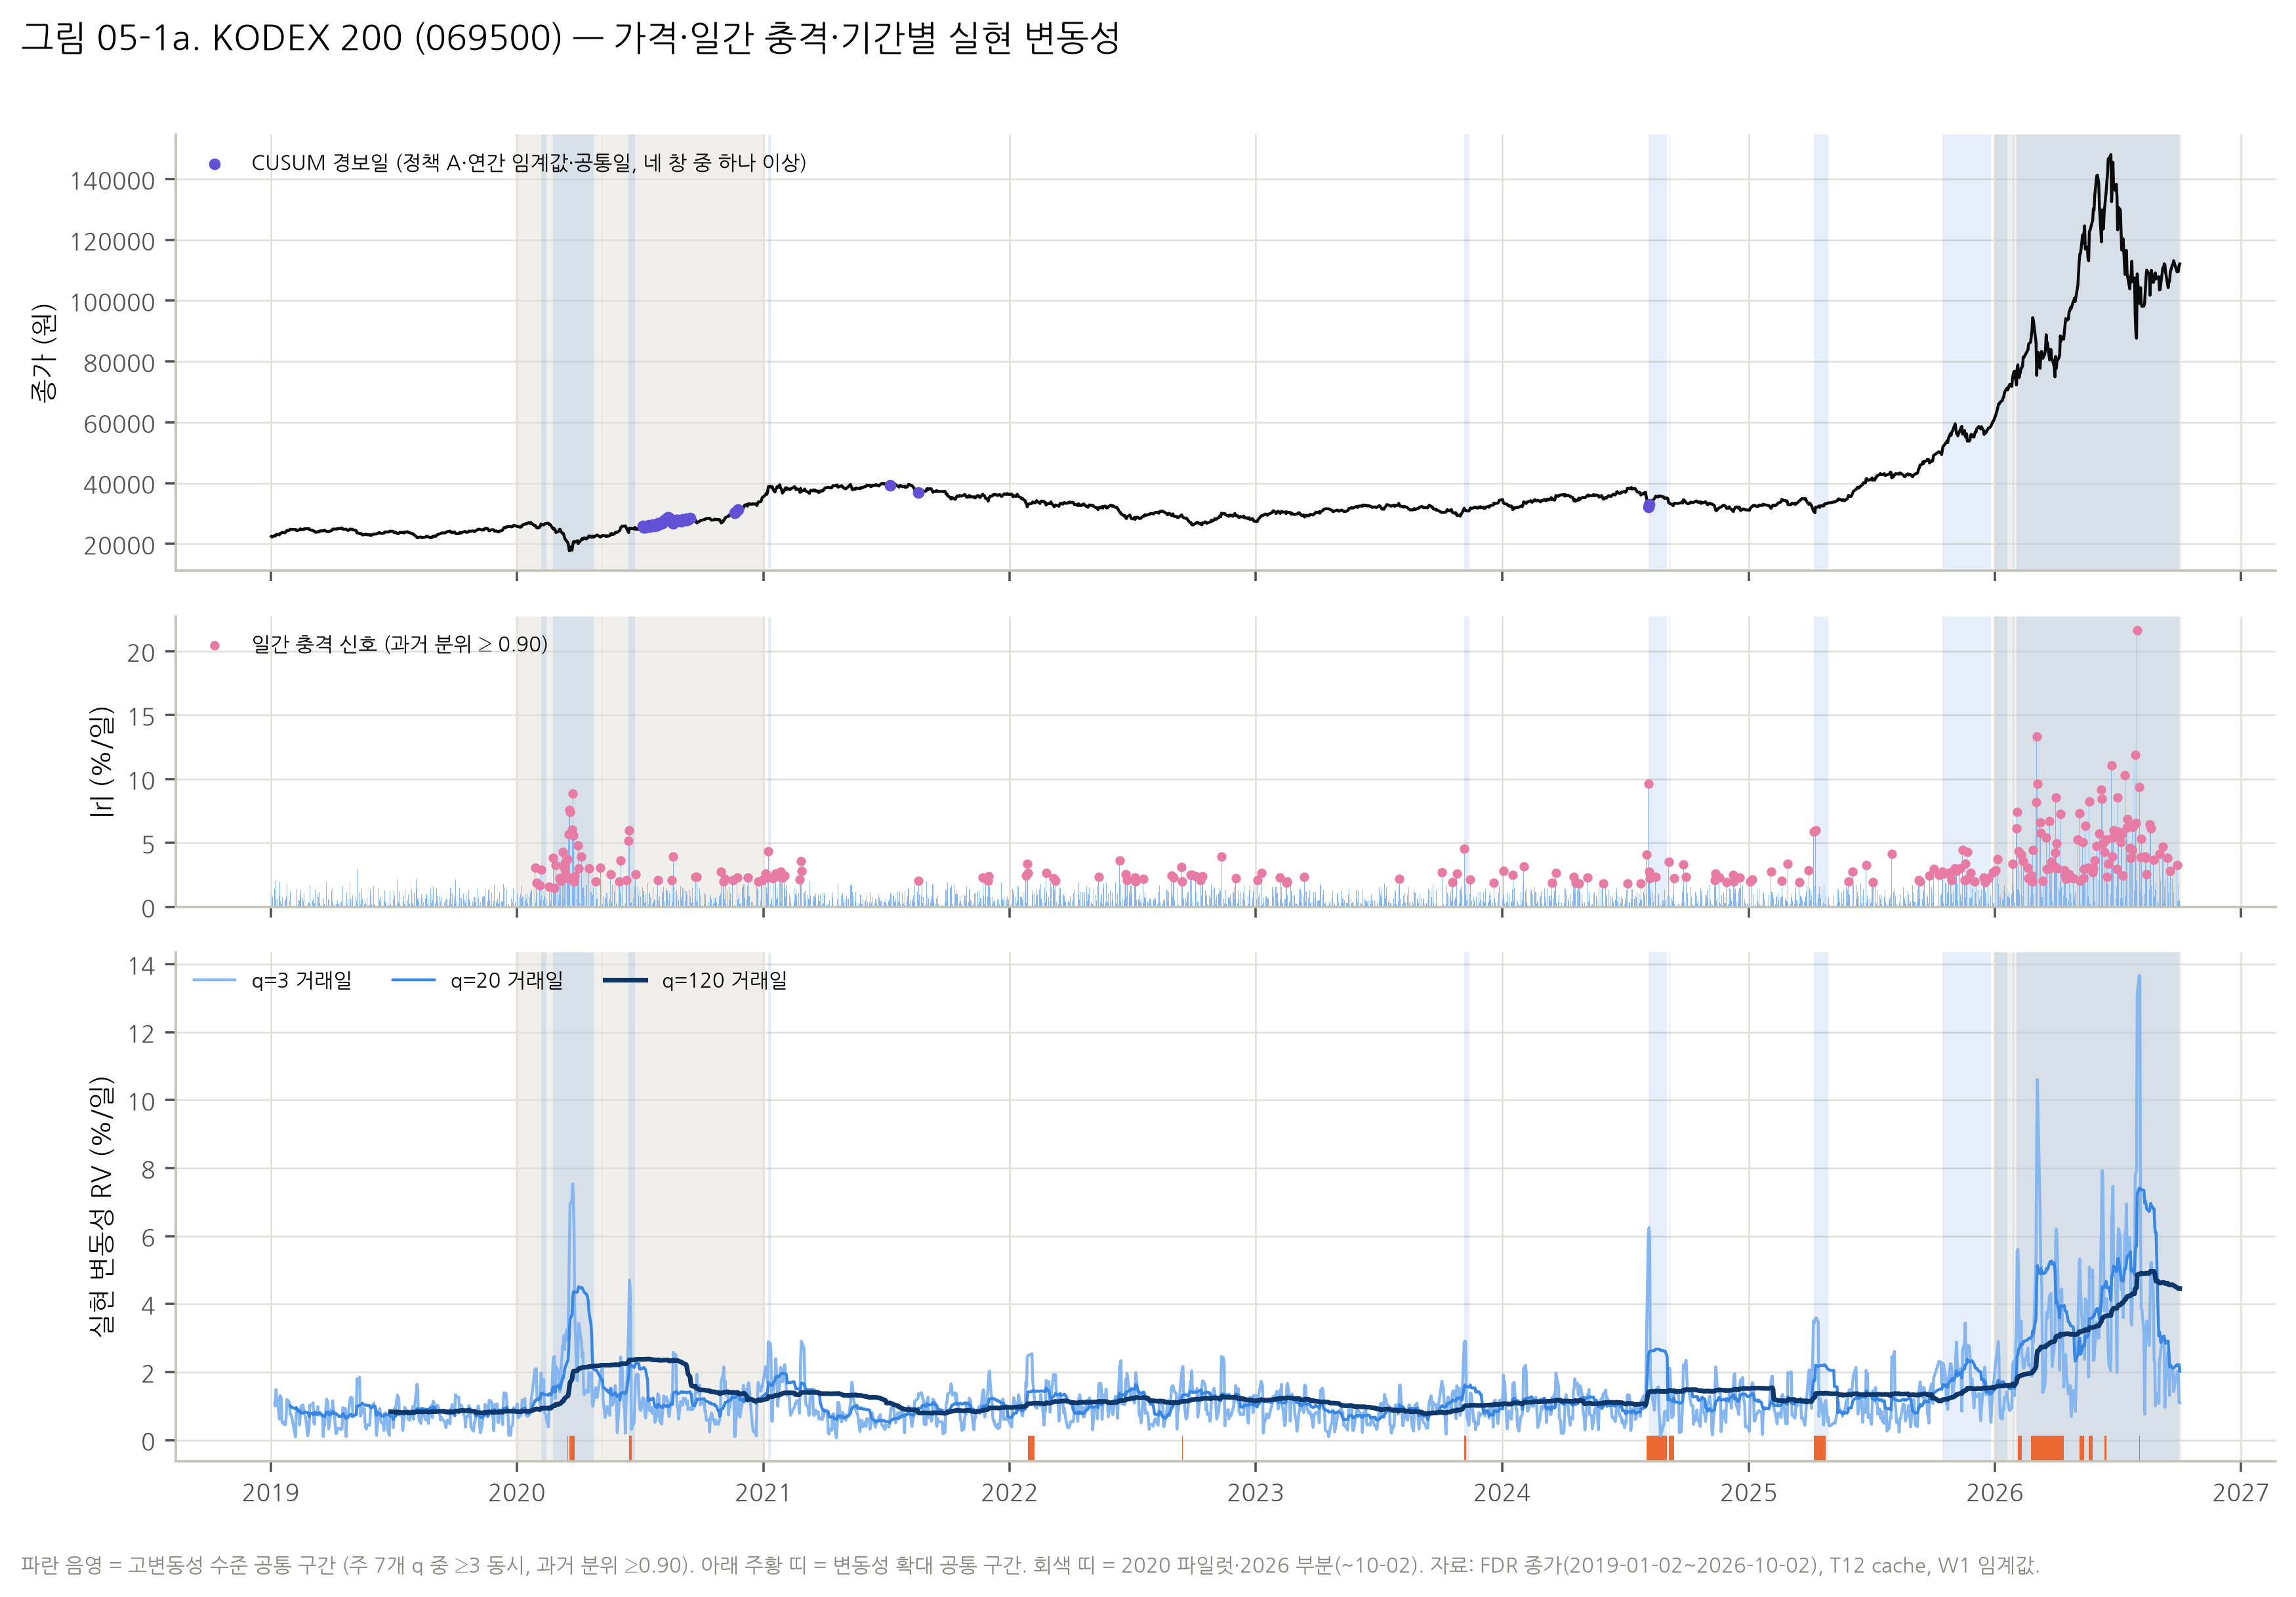

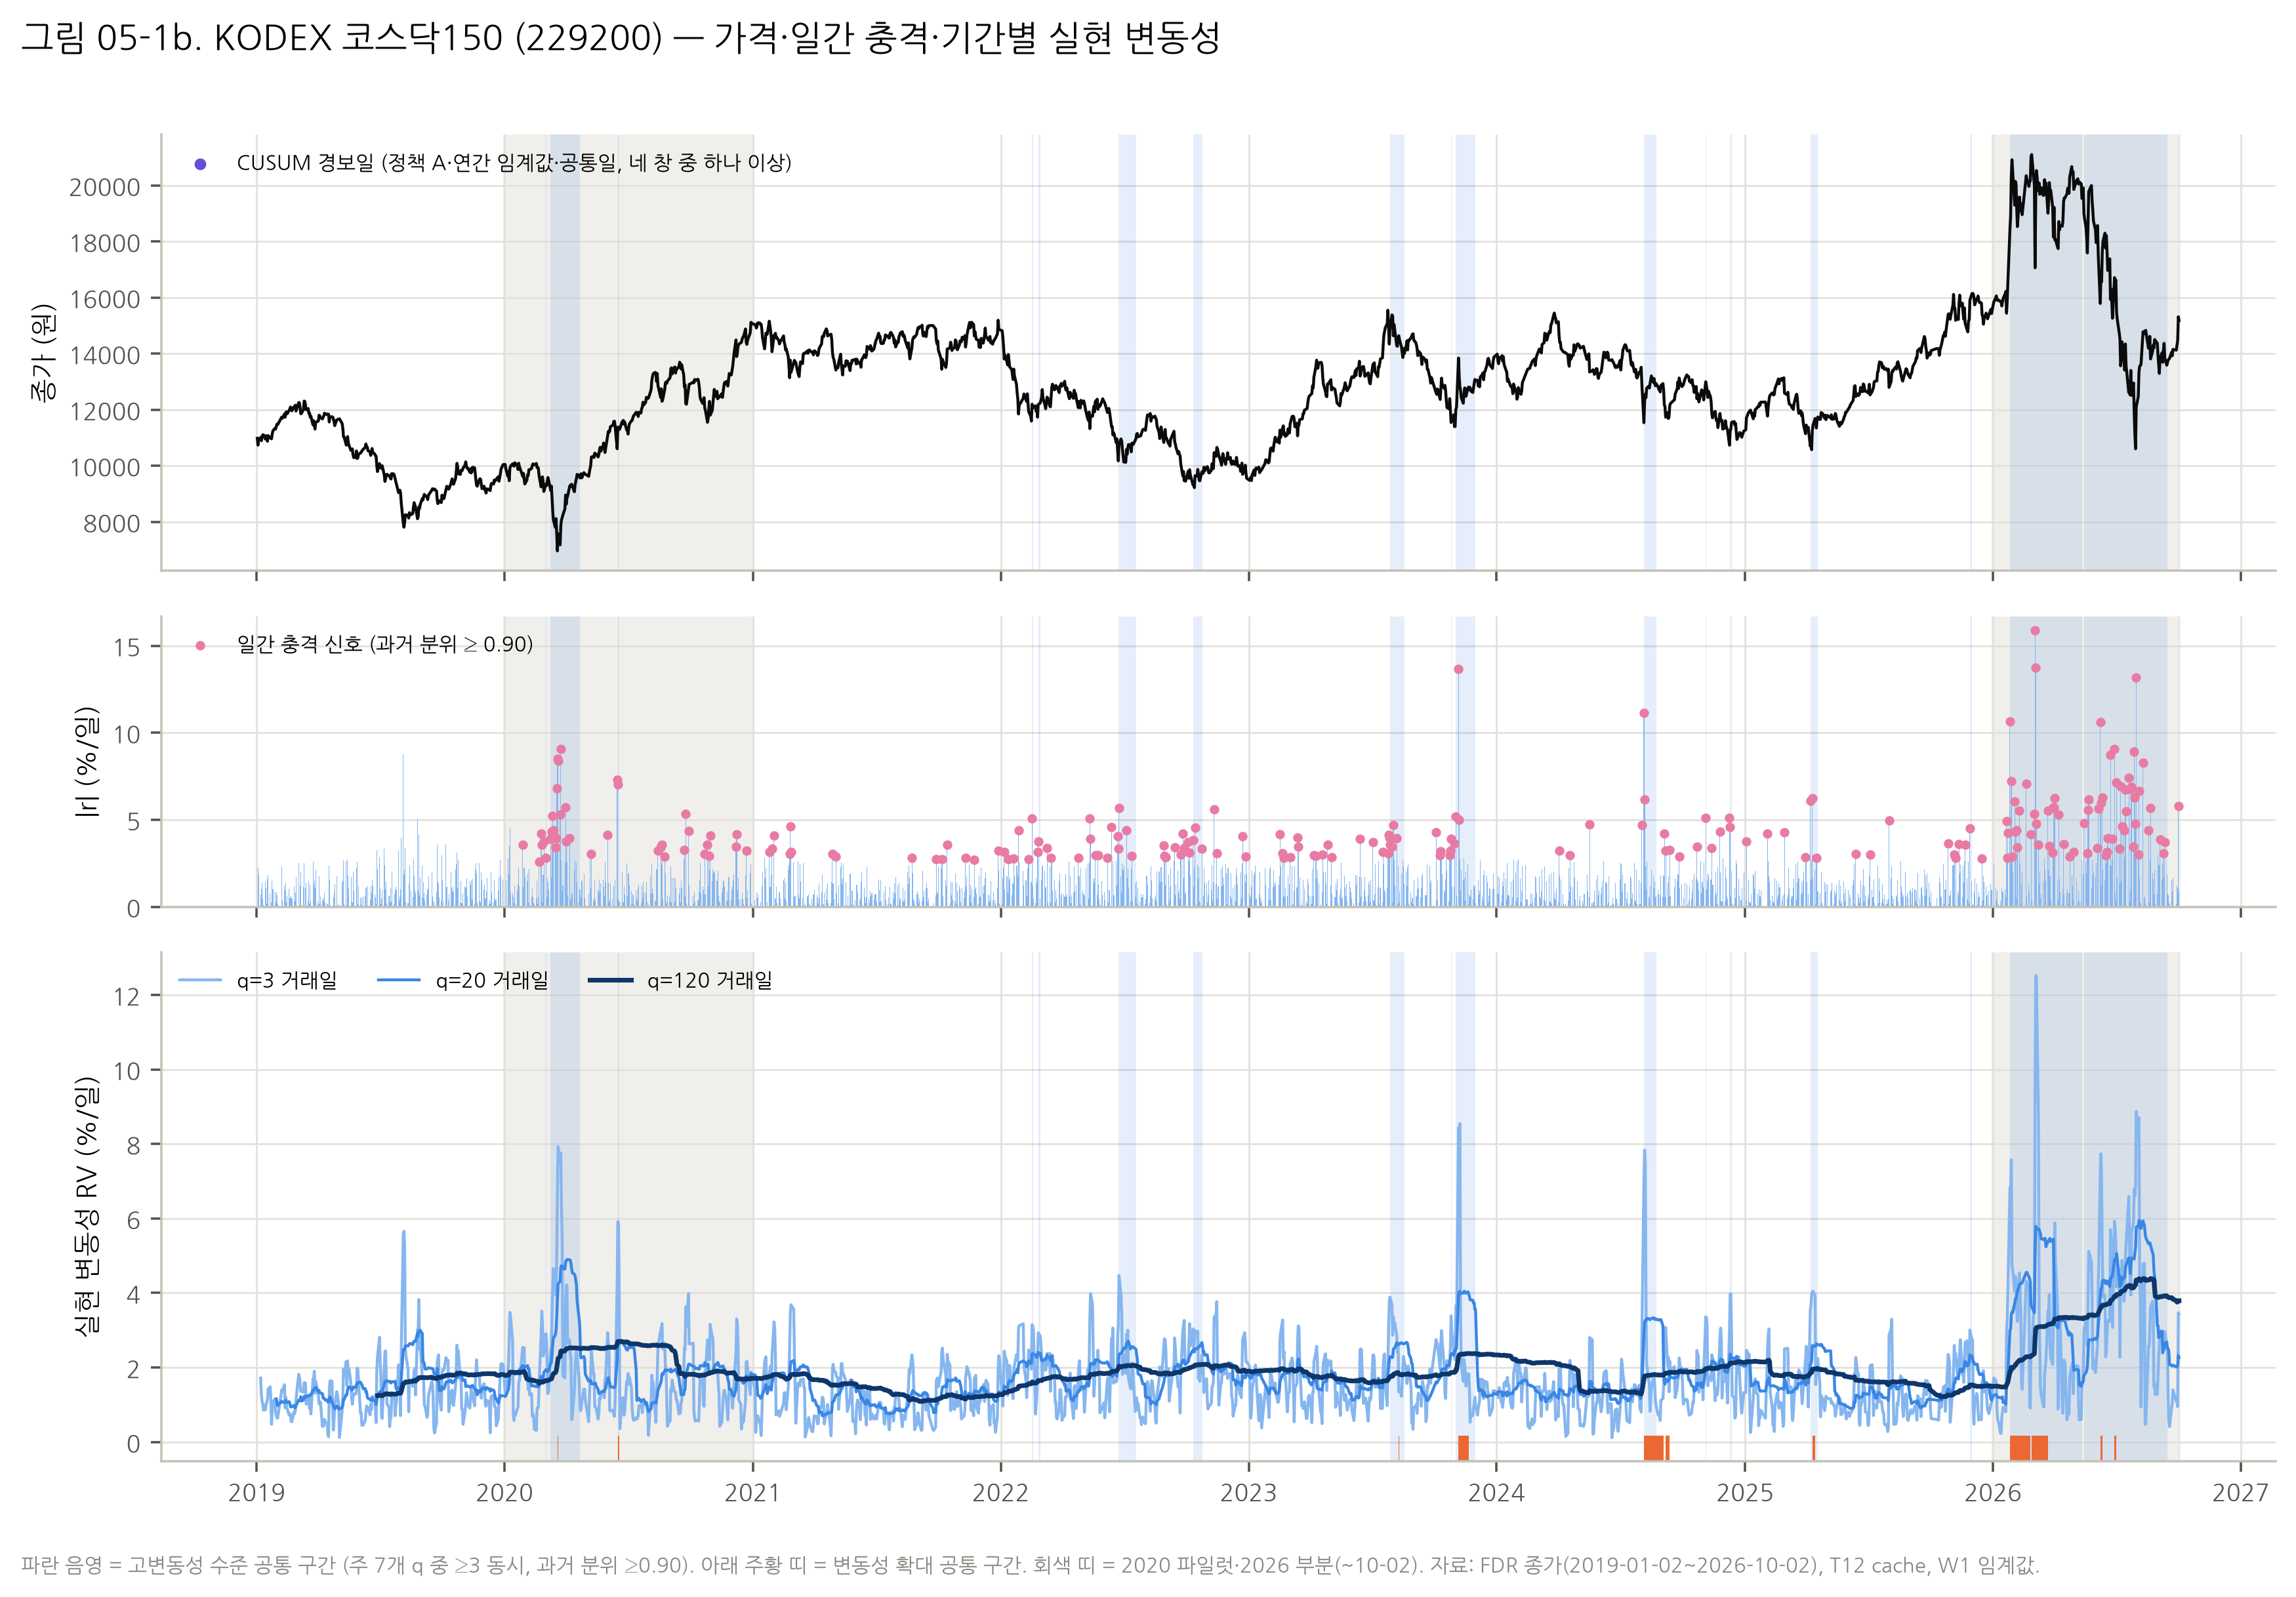

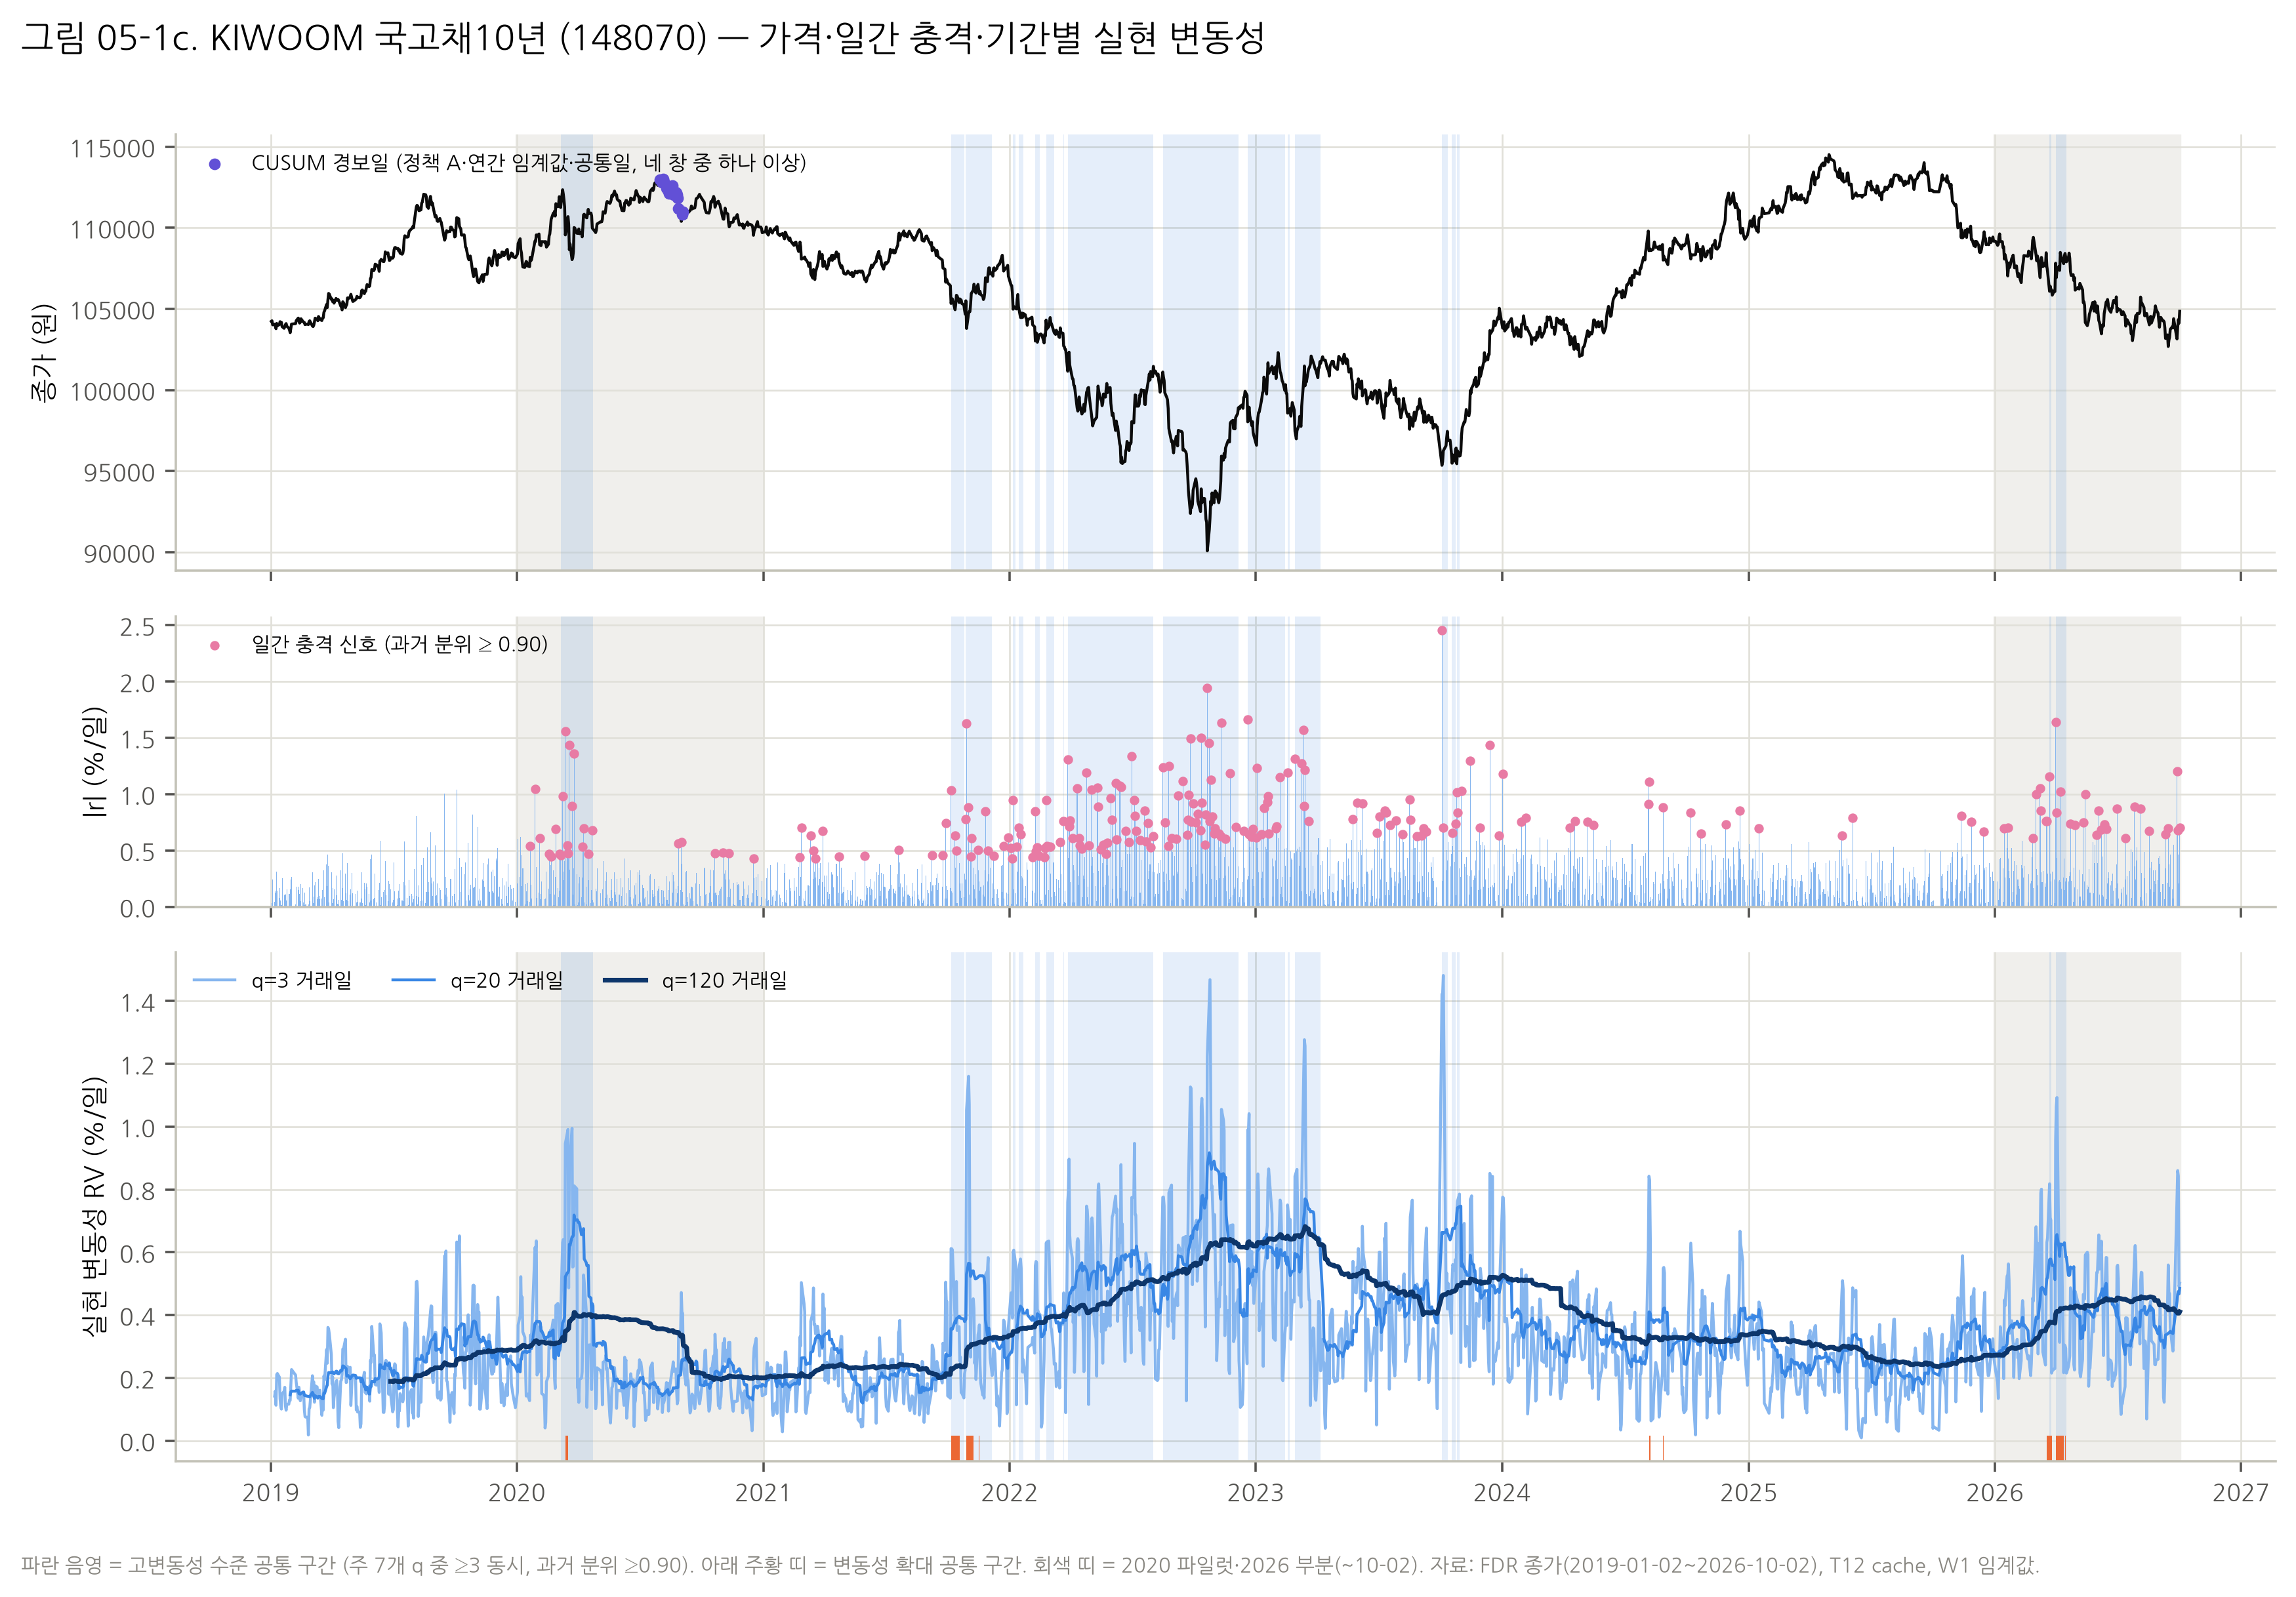

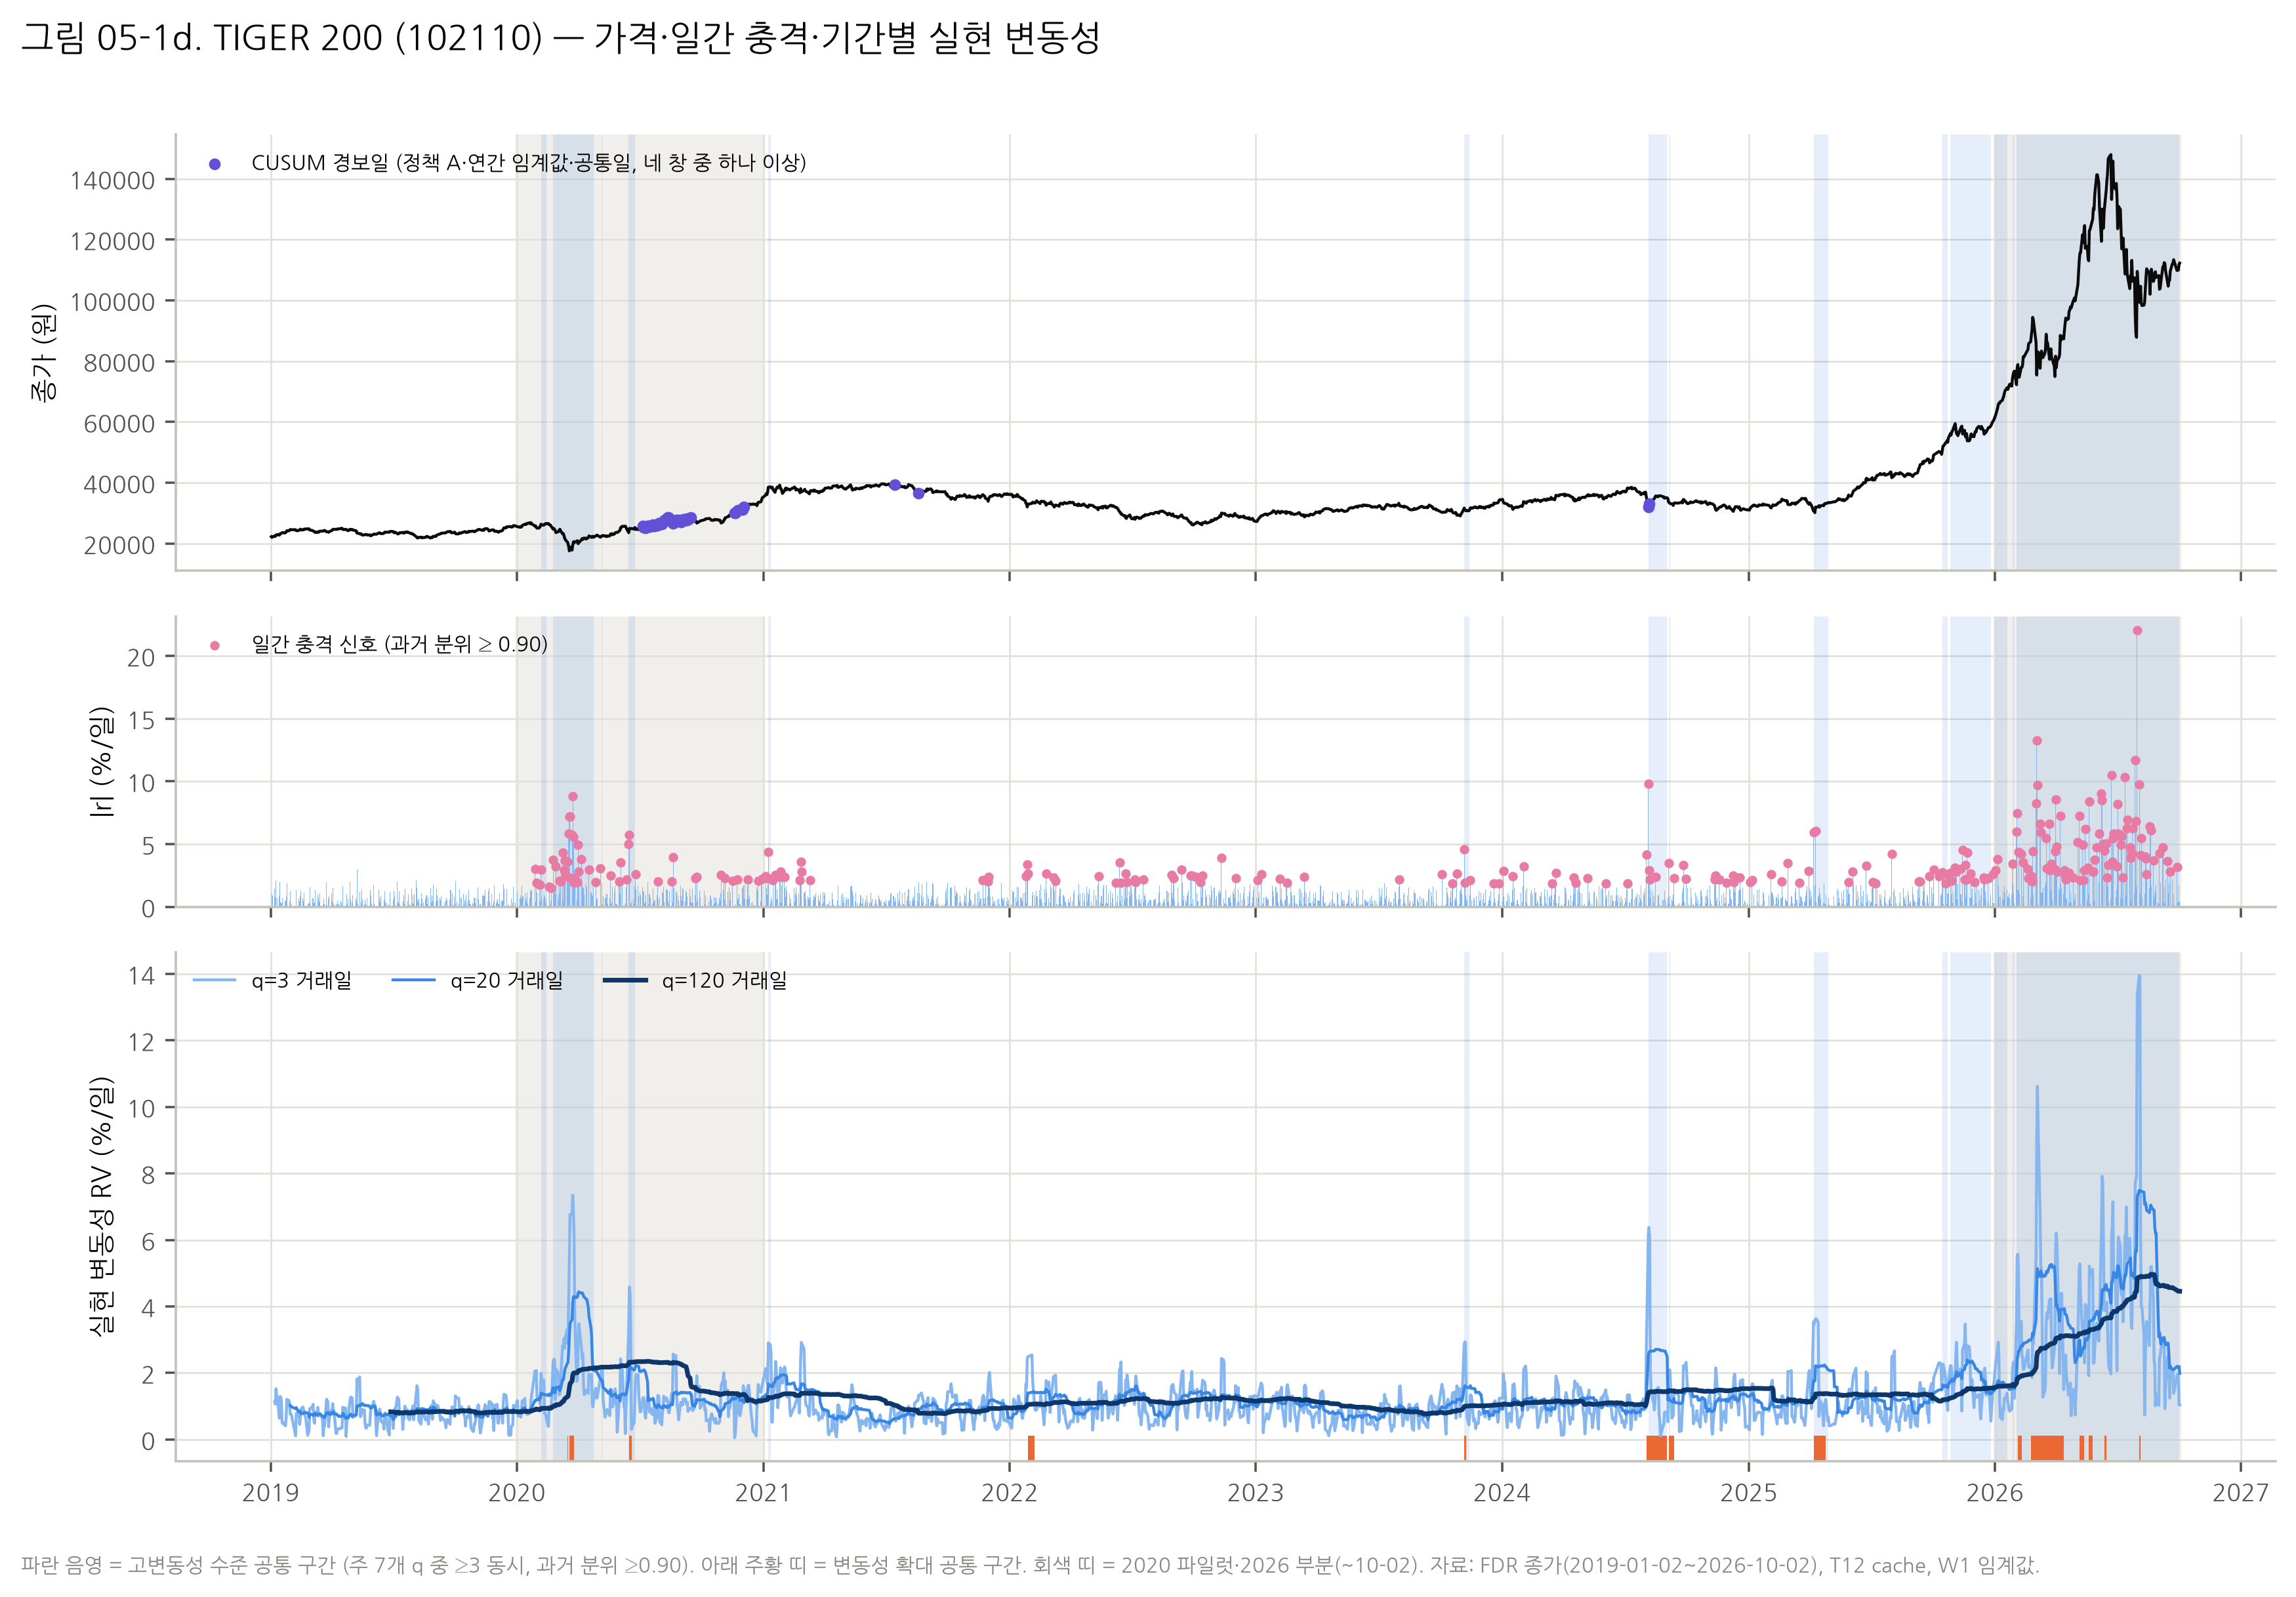

In [10]:
# 그림 05-1: 대표 4종의 가격·일간 충격·기간별 실현 변동성 3단 패널.
from r2h.multihorizon import figures as F  # W2 그림 함수

REP = CFG["representative_tickers"]  # 대표 4종
NAMES = UNI.set_index("ticker").name.to_dict()  # 코드 → 이름
CUS = S05["cusum"]  # 일별 CUSUM 재계산 (정책·창·임계값·표본별 상태)
MAIN_C = CUS[CUS.policy == "A"].set_index(["ticker", "date"])  # 주 CUSUM: 정책 A
FIG_FILES = []  # 그림 파일 목록
for k, t in enumerate(REP):  # 대표 4종 반복
    close = S05["prices"][t].set_index("Date").Close  # 종가
    ft = FEAT[FEAT.ticker == t]  # 해당 ETF 특징
    alarm_any = MAIN_C.loc[t][[f"pipe_common_w{w}" for w in CFG["cusum_windows"]]].eq("ALARM").any(axis=1)  # 네 창 중 하나라도 경보
    FIG_FILES += F.three_panel(t, NAMES[t], close, ft, IV[IV.ticker == t], alarm_any, FIG, f"05-1{'abcd'[k]}")  # 그림 저장
    display(Image(filename=str(FIG_FILES[-2]), width=900))  # PNG 표시

**그림 05-1 해석.**
- 069500·102110 두 KOSPI200 상품의 음영(고변동성 공통 구간)이 거의 같다. 같은 노출이기 때문이다.
- 국고채10년 148070 은 2022 년 전체가 고변동성 수준이다. 주식형 ETF 는 2022 가 아니라 2024-08 과 2025 말–2026 에 고변동성 구간이 몰린다.
- 보라색 CUSUM 경보는 RV 가 높은 구간과 자주 엇갈린다.
  - 예: 069500 의 2026 고변동성 구간에는 경보가 없다. 다만 그 구간의 앞부분(연초 119 거래일)은 CUSUM 을 계산할 수 없다.
  - CUSUM 은 SVR–GARCH 예측분산으로 나눈 잔차의 창 내 변화를 본다. 그래서 '변동성이 높다' 는 사실 자체에는 반응하지 않는다 (§13).

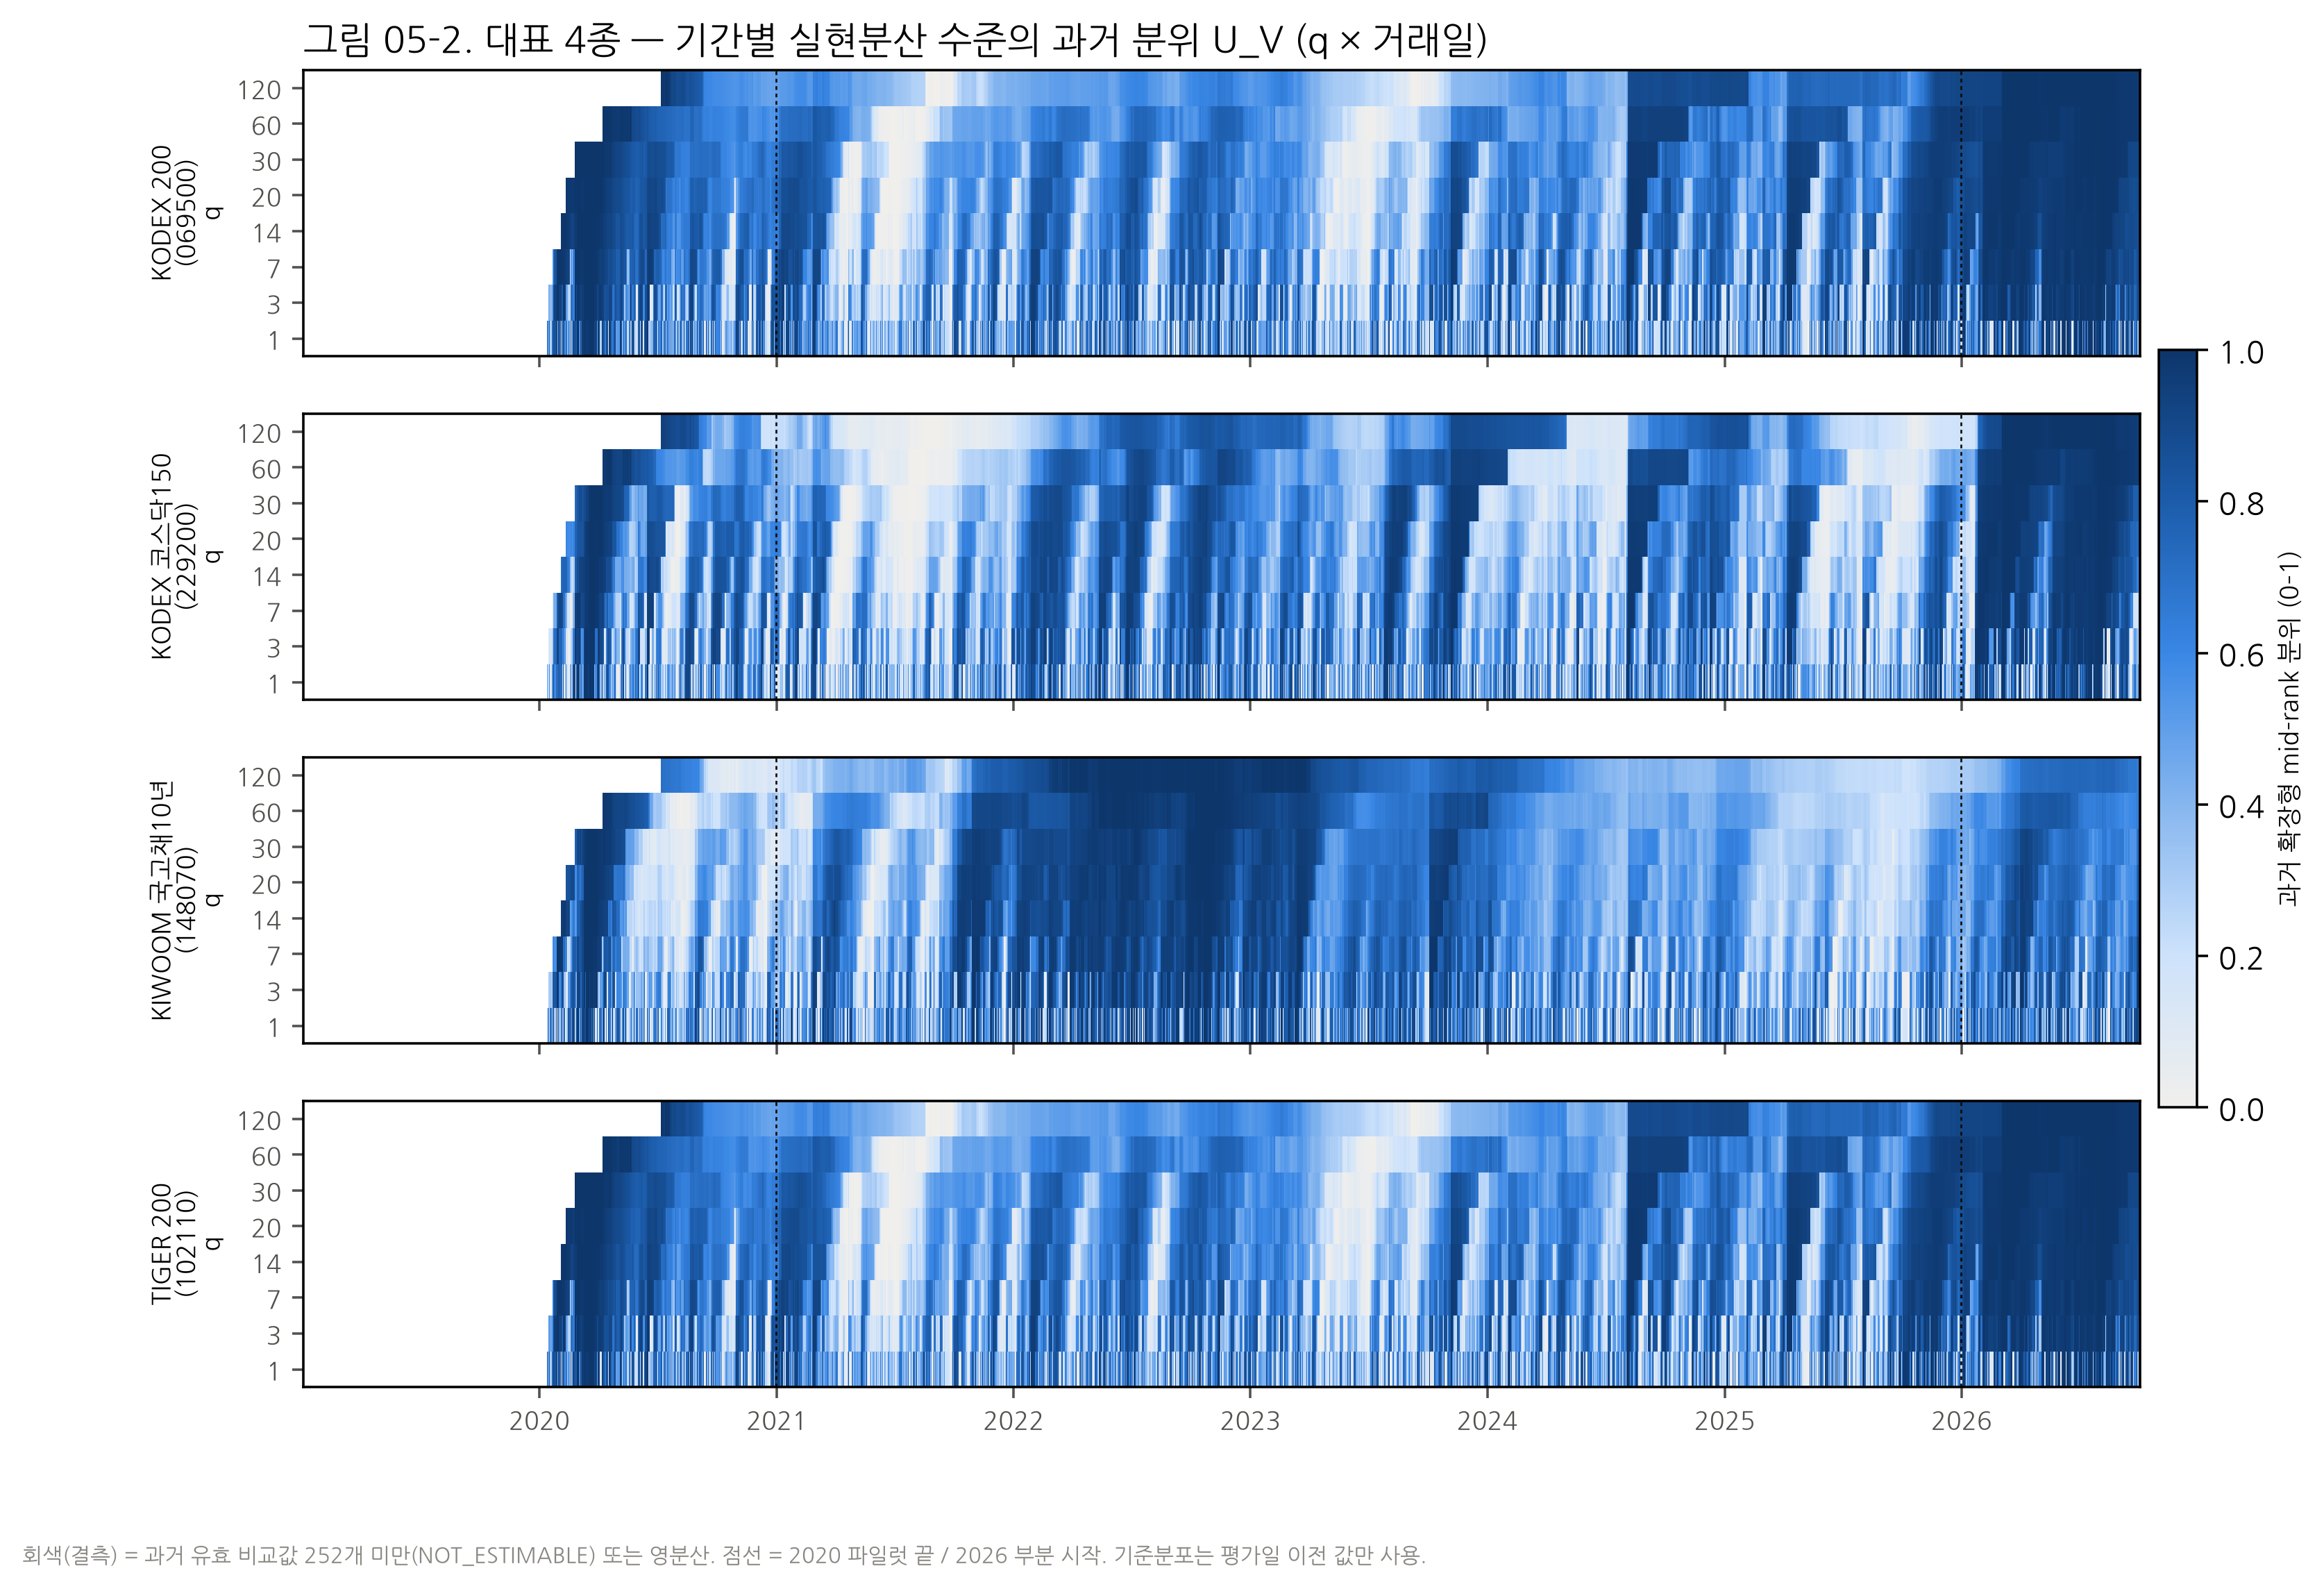

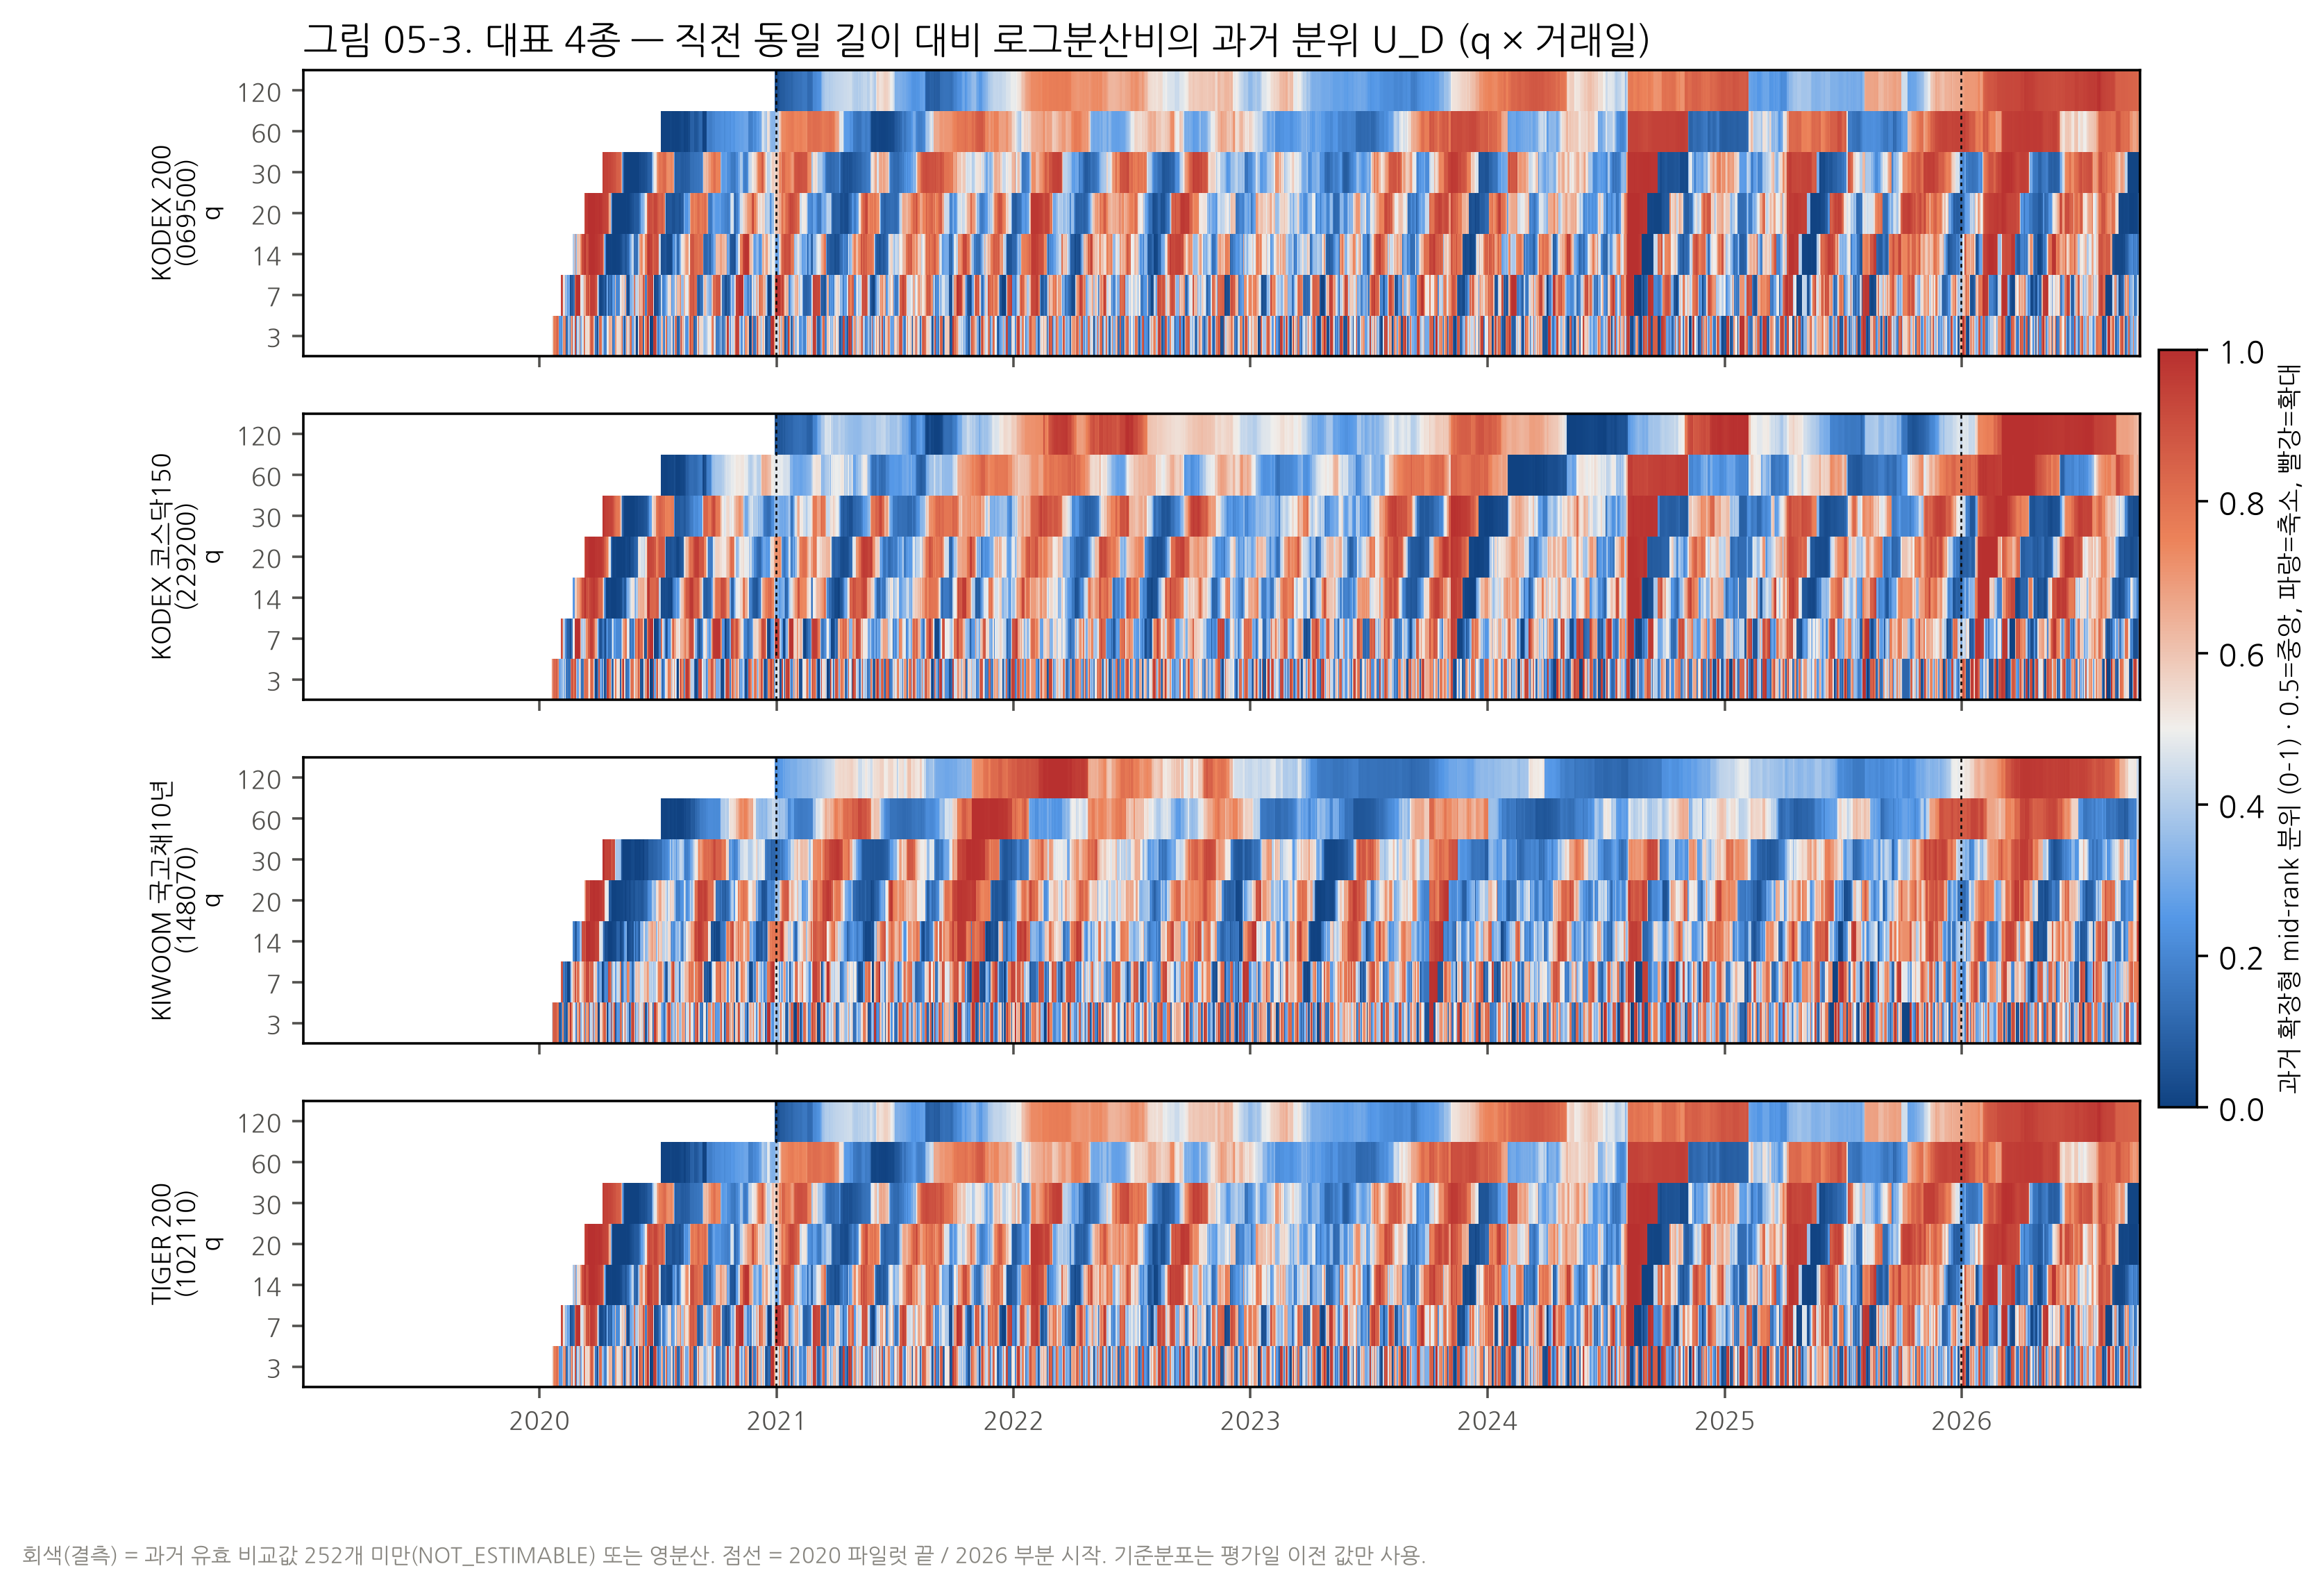

In [11]:
# 그림 05-2·05-3: 대표 4종 × 8개 q 의 과거 분위 히트맵 (수준 U_V, 변화 U_D).
items = [(t, NAMES[t], FEAT[FEAT.ticker == t]) for t in REP]  # 대표 4종 입력
FIG_FILES += F.quantile_heatmaps(items, "U_V", FIG, "05-2", "대표 4종 — 기간별 실현분산 수준의 과거 분위 U_V (q × 거래일)")  # 수준 히트맵
display(Image(filename=str(FIG_FILES[-2]), width=900))  # 표시
FIG_FILES += F.quantile_heatmaps(items, "U_D", FIG, "05-3", "대표 4종 — 직전 동일 길이 대비 로그분산비의 과거 분위 U_D (q × 거래일)")  # 변화 히트맵
display(Image(filename=str(FIG_FILES[-2]), width=900))  # 표시

**그림 05-2·05-3 해석.**
- 수준 히트맵(05-2)은 긴 q 에서 넓은 짙은 띠를 보인다. 상태가 오래 지속되기 때문이다.
- 변화 히트맵(05-3)은 짧은 q 에서 빨강·파랑이 빠르게 번갈아 나타난다. 긴 q 에서는 확대 뒤 축소가 반 박자 늦게 이어진다.
- 두 히트맵의 짙은 영역은 겹치는 날도 있지만 대부분 어긋난다. 수준이 높은 상태는 오래 지속되고, 확대(빨강)는 그 상태로 들어가는 짧은 시기에 몰린다.
- 이것이 '수준과 변화는 다른 구간을 강조한다' 는 관찰의 그림 근거다. 수치는 §14 의 Jaccard 와 겹침 비율로 확인한다.

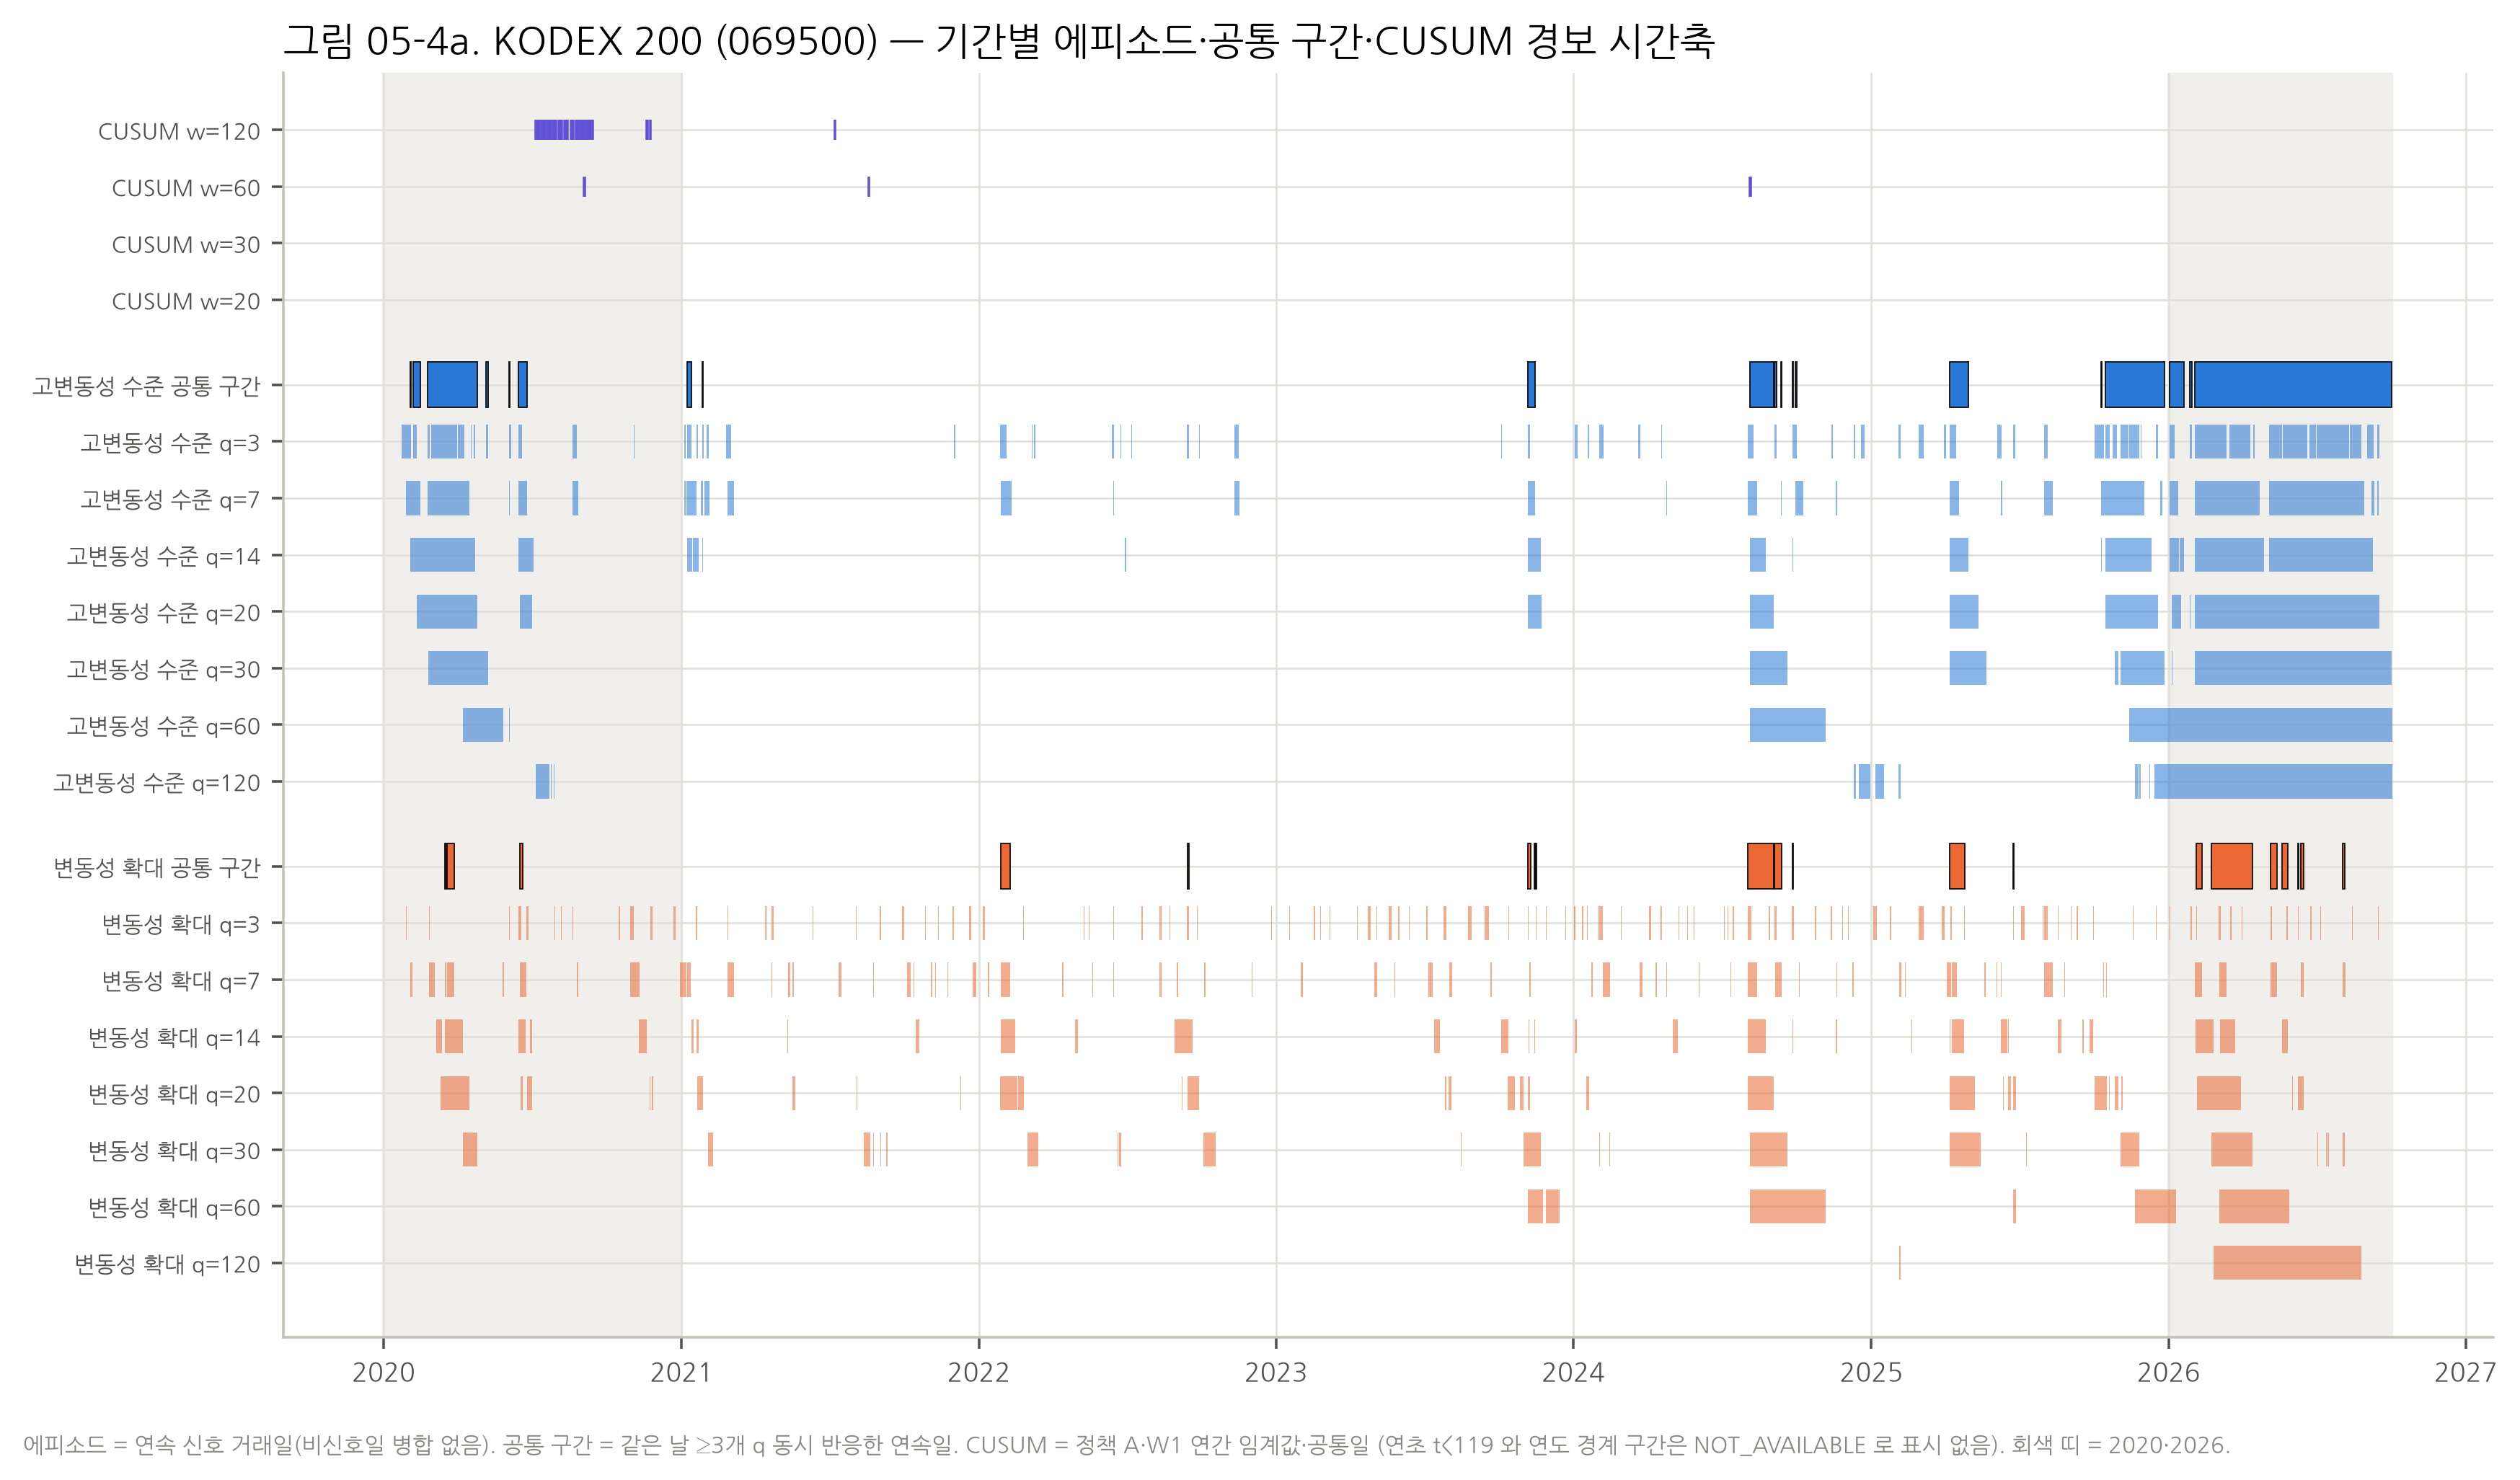

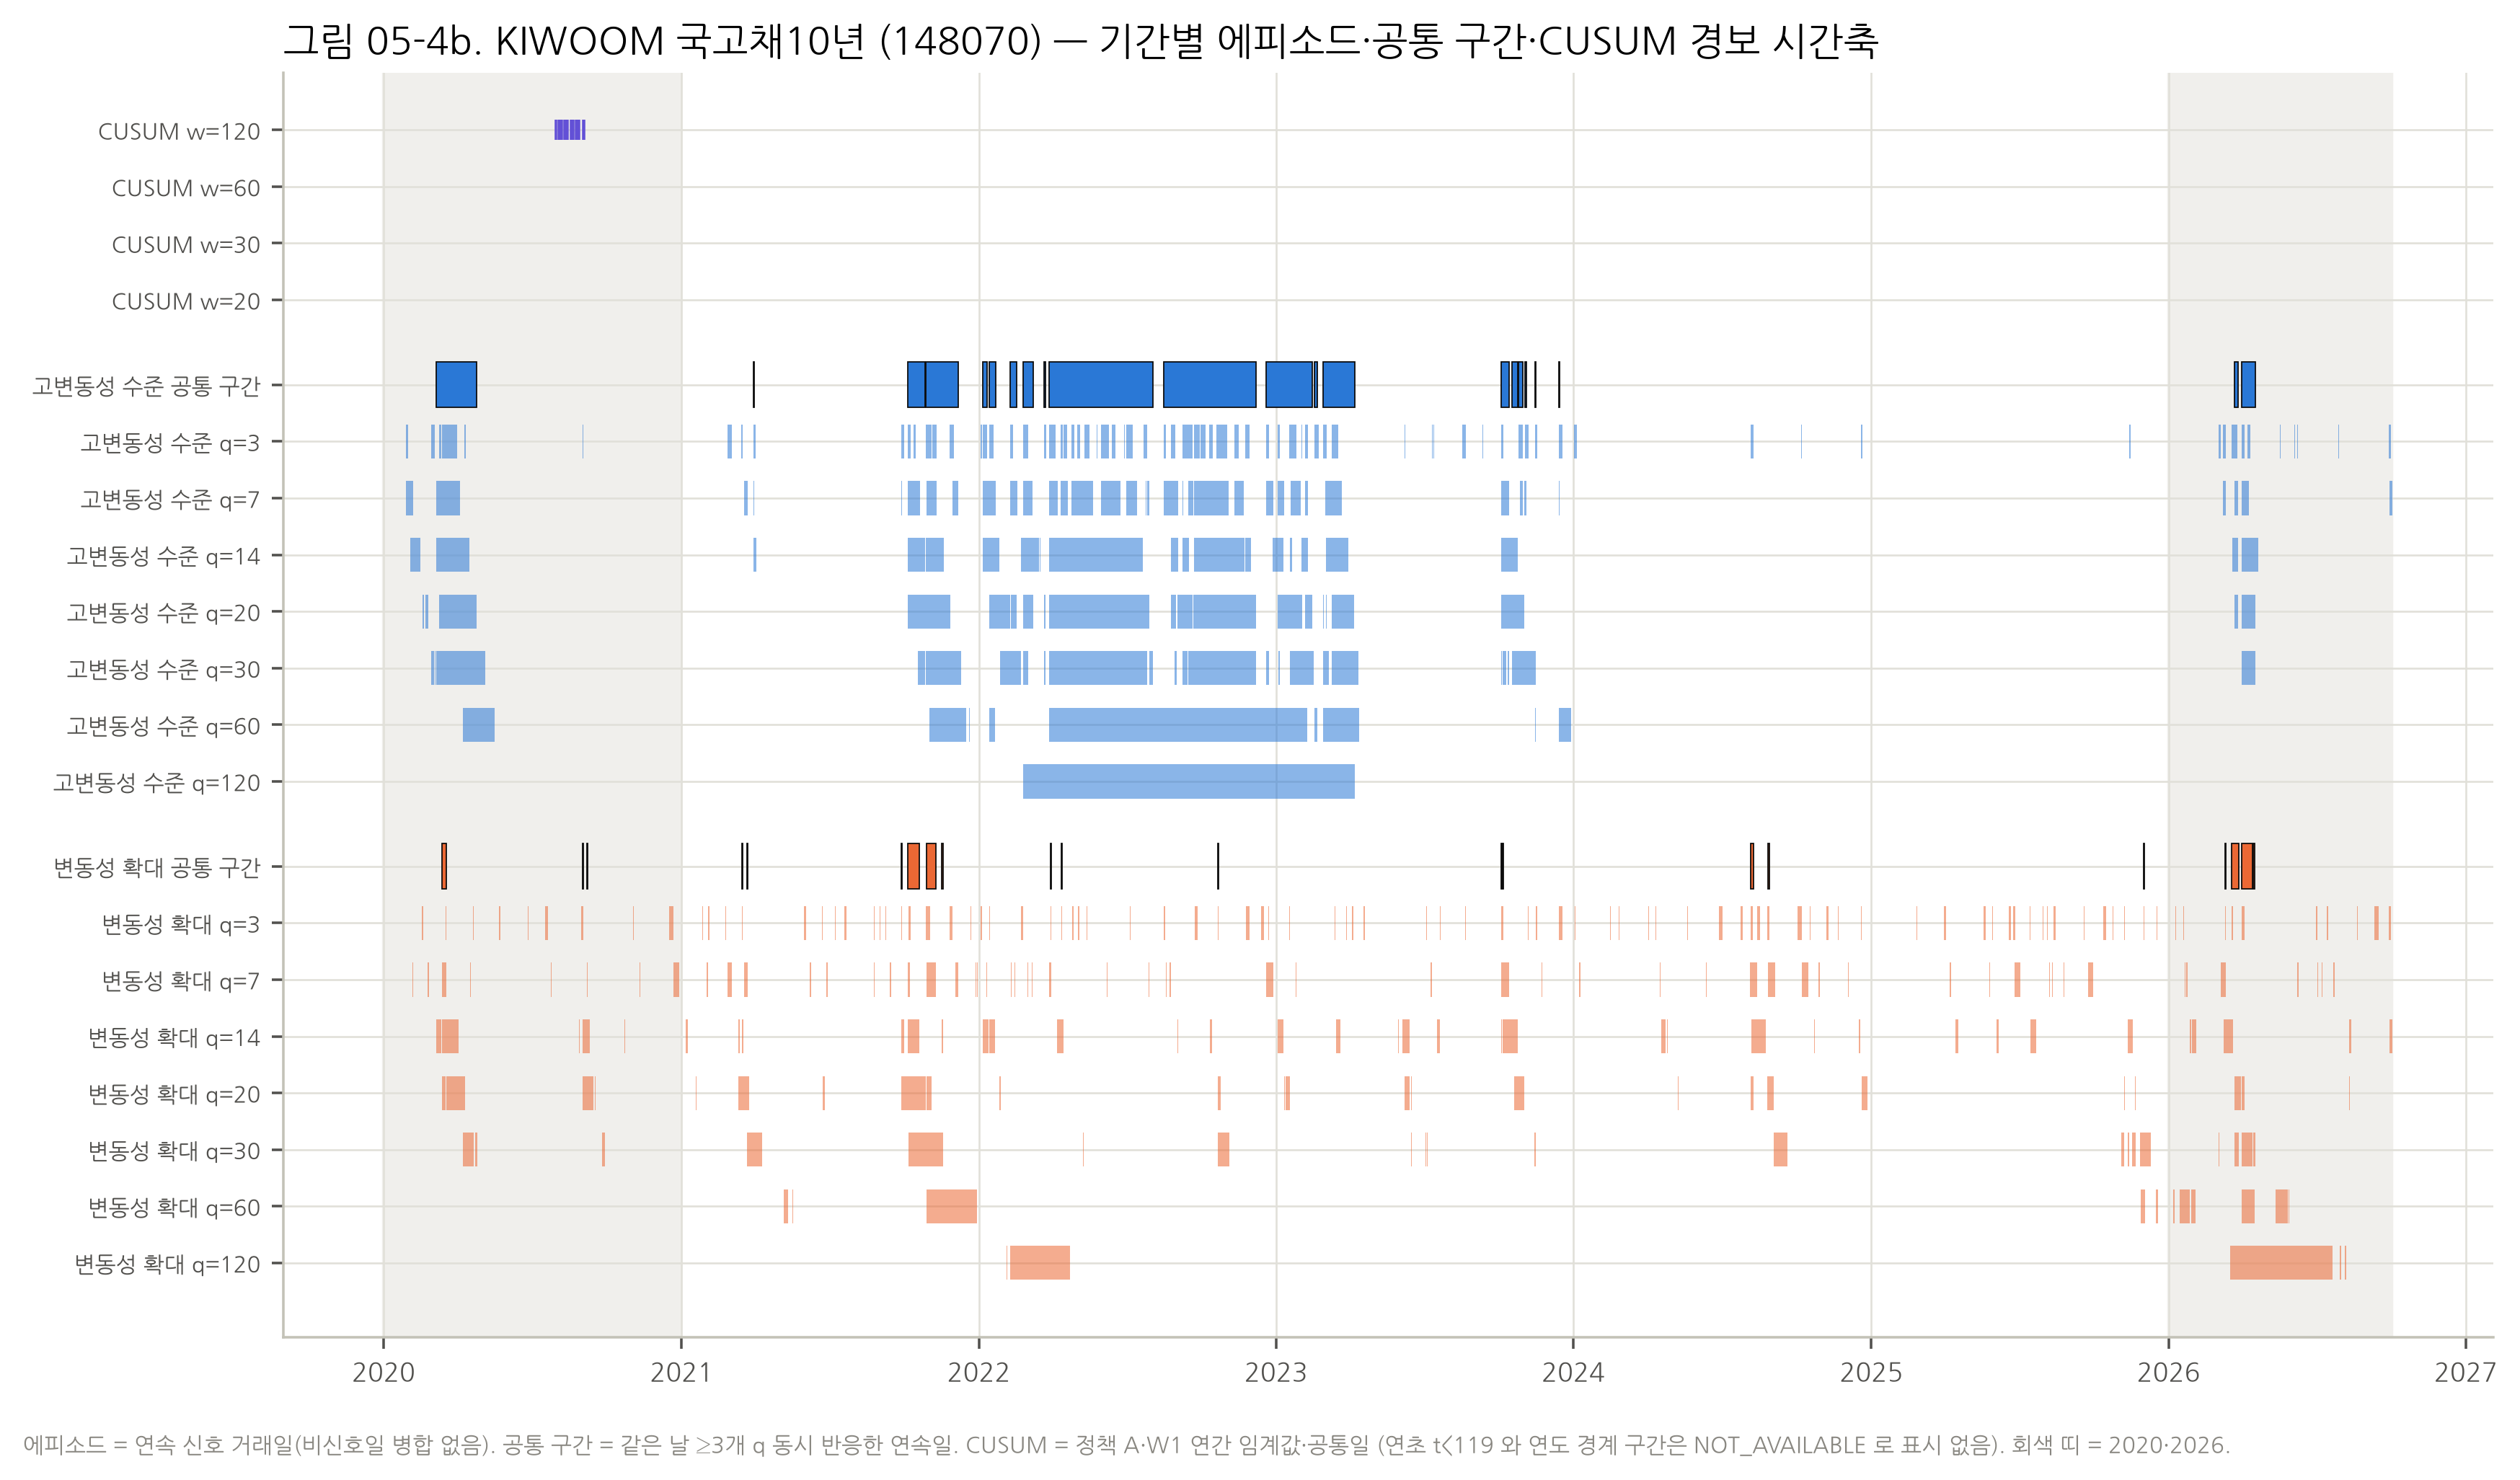

In [12]:
# 그림 05-4: 069500 과 148070 의 기간별 에피소드·공통 구간·CUSUM 창별 경보 시간축.
for t, k in (("069500", "a"), ("148070", "b")):  # 주식형·채권형 대비
    cw = {w: MAIN_C.loc[t][f"pipe_common_w{w}"].eq("ALARM") for w in CFG["cusum_windows"]}  # 창별 경보일
    FIG_FILES += F.episode_timeline(t, NAMES[t], EP[EP.ticker == t], IV[IV.ticker == t], cw, FIG, f"05-4{k}")  # 시간축 저장
    display(Image(filename=str(FIG_FILES[-2]), width=900))  # 표시

**그림 05-4 해석.**
- 짧은 q(3·7)의 에피소드는 잘게 끊긴다. 긴 q(60·120)는 몇 달짜리 막대 하나다.
- 공통 구간(진한 막대)은 그 둘이 실제로 겹친 날만 남긴다. 그래서 긴 q 막대보다 훨씬 짧다.
- CUSUM 경보(맨 위 네 줄)는 각 연도 앞쪽 약 119 거래일 동안 표시가 없다. 공통일 규칙 때문에 계산할 수 없는 기간이다 (`NOT_AVAILABLE`, 무경보 아님).

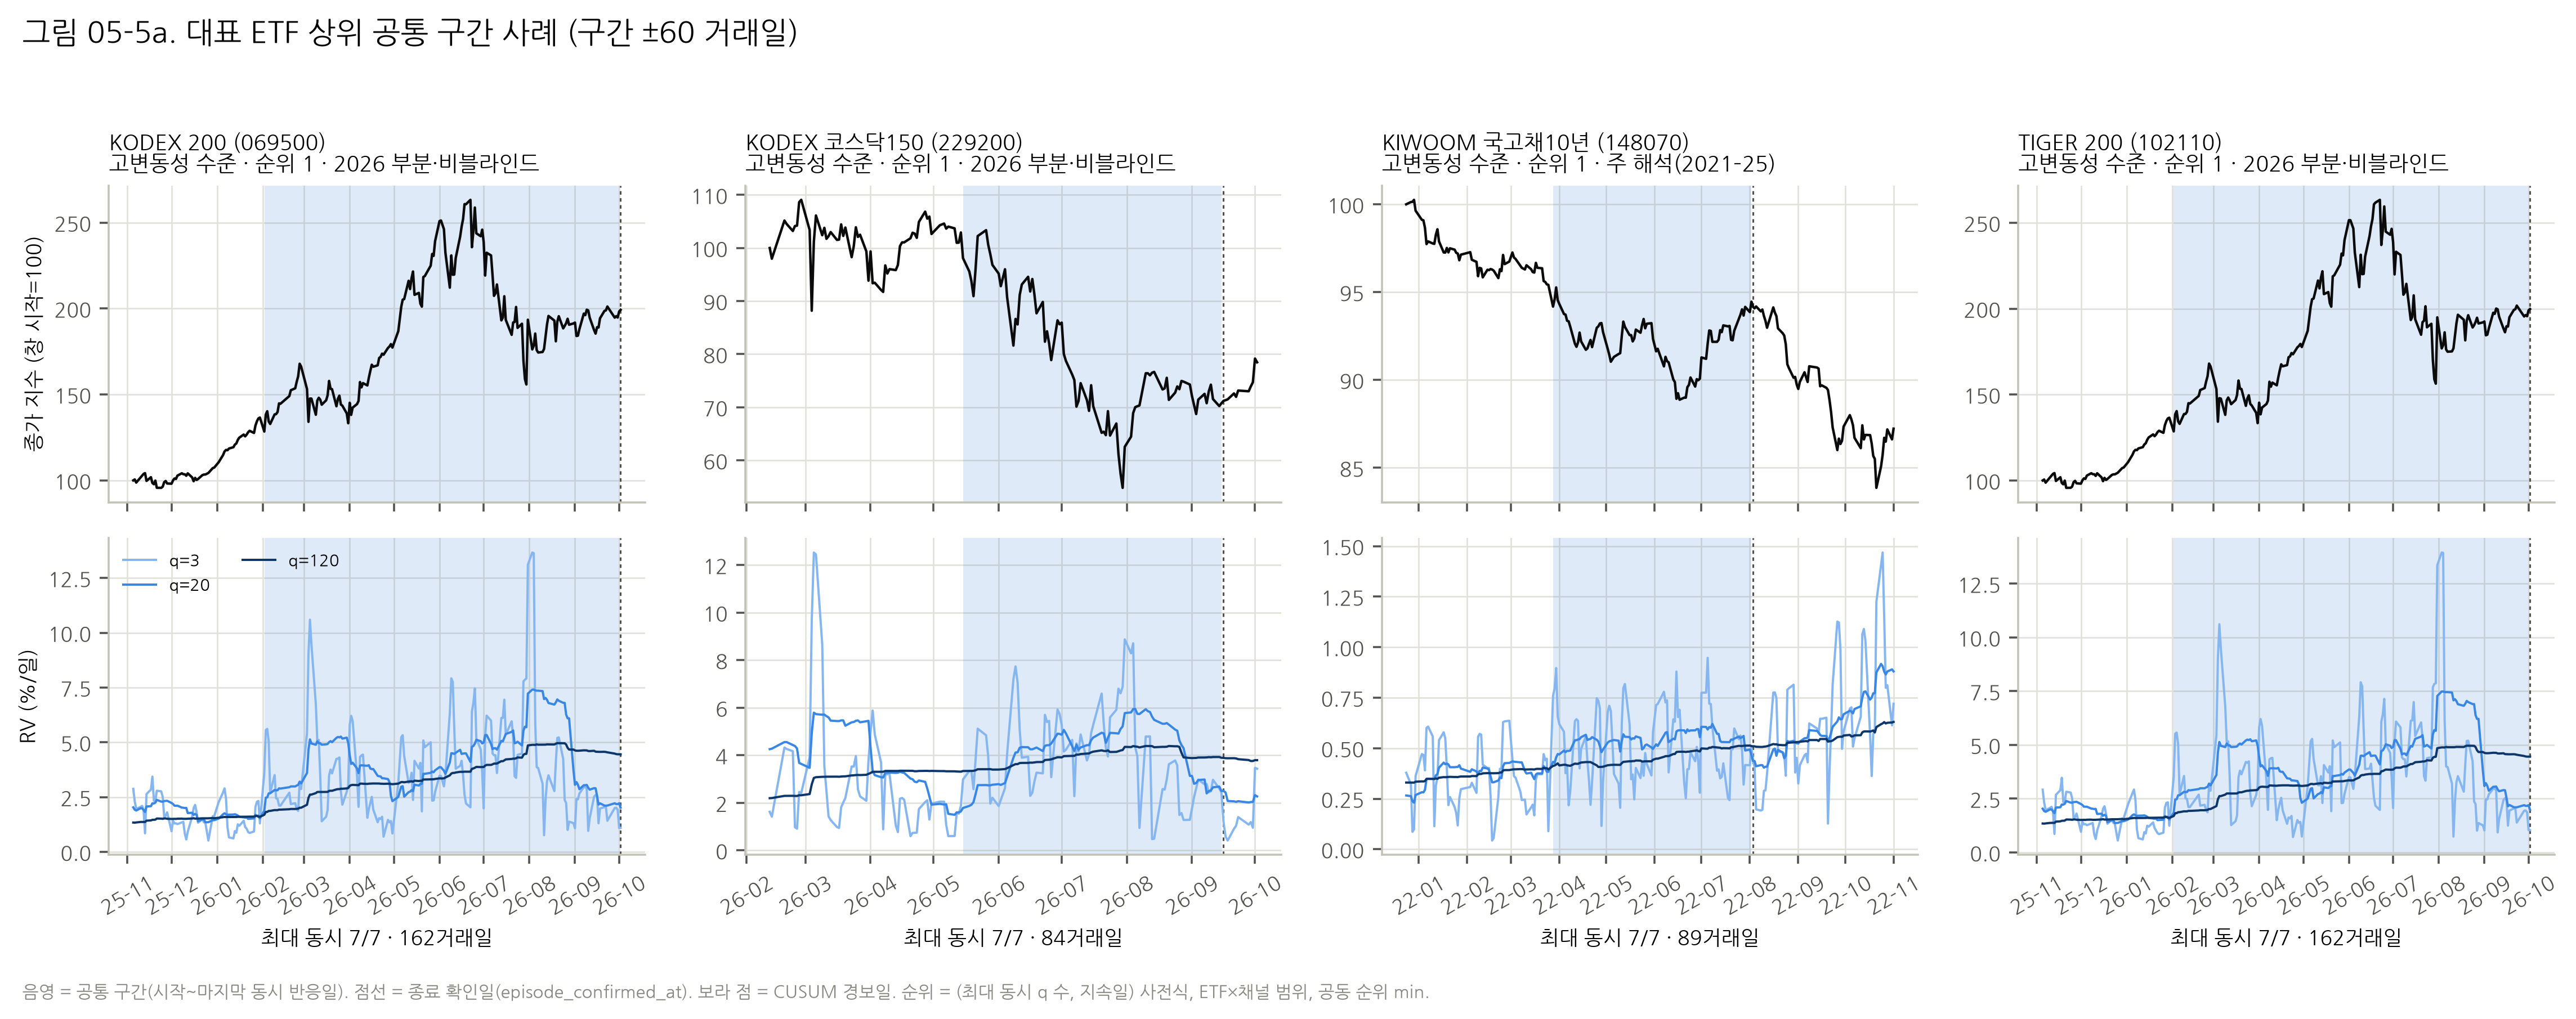

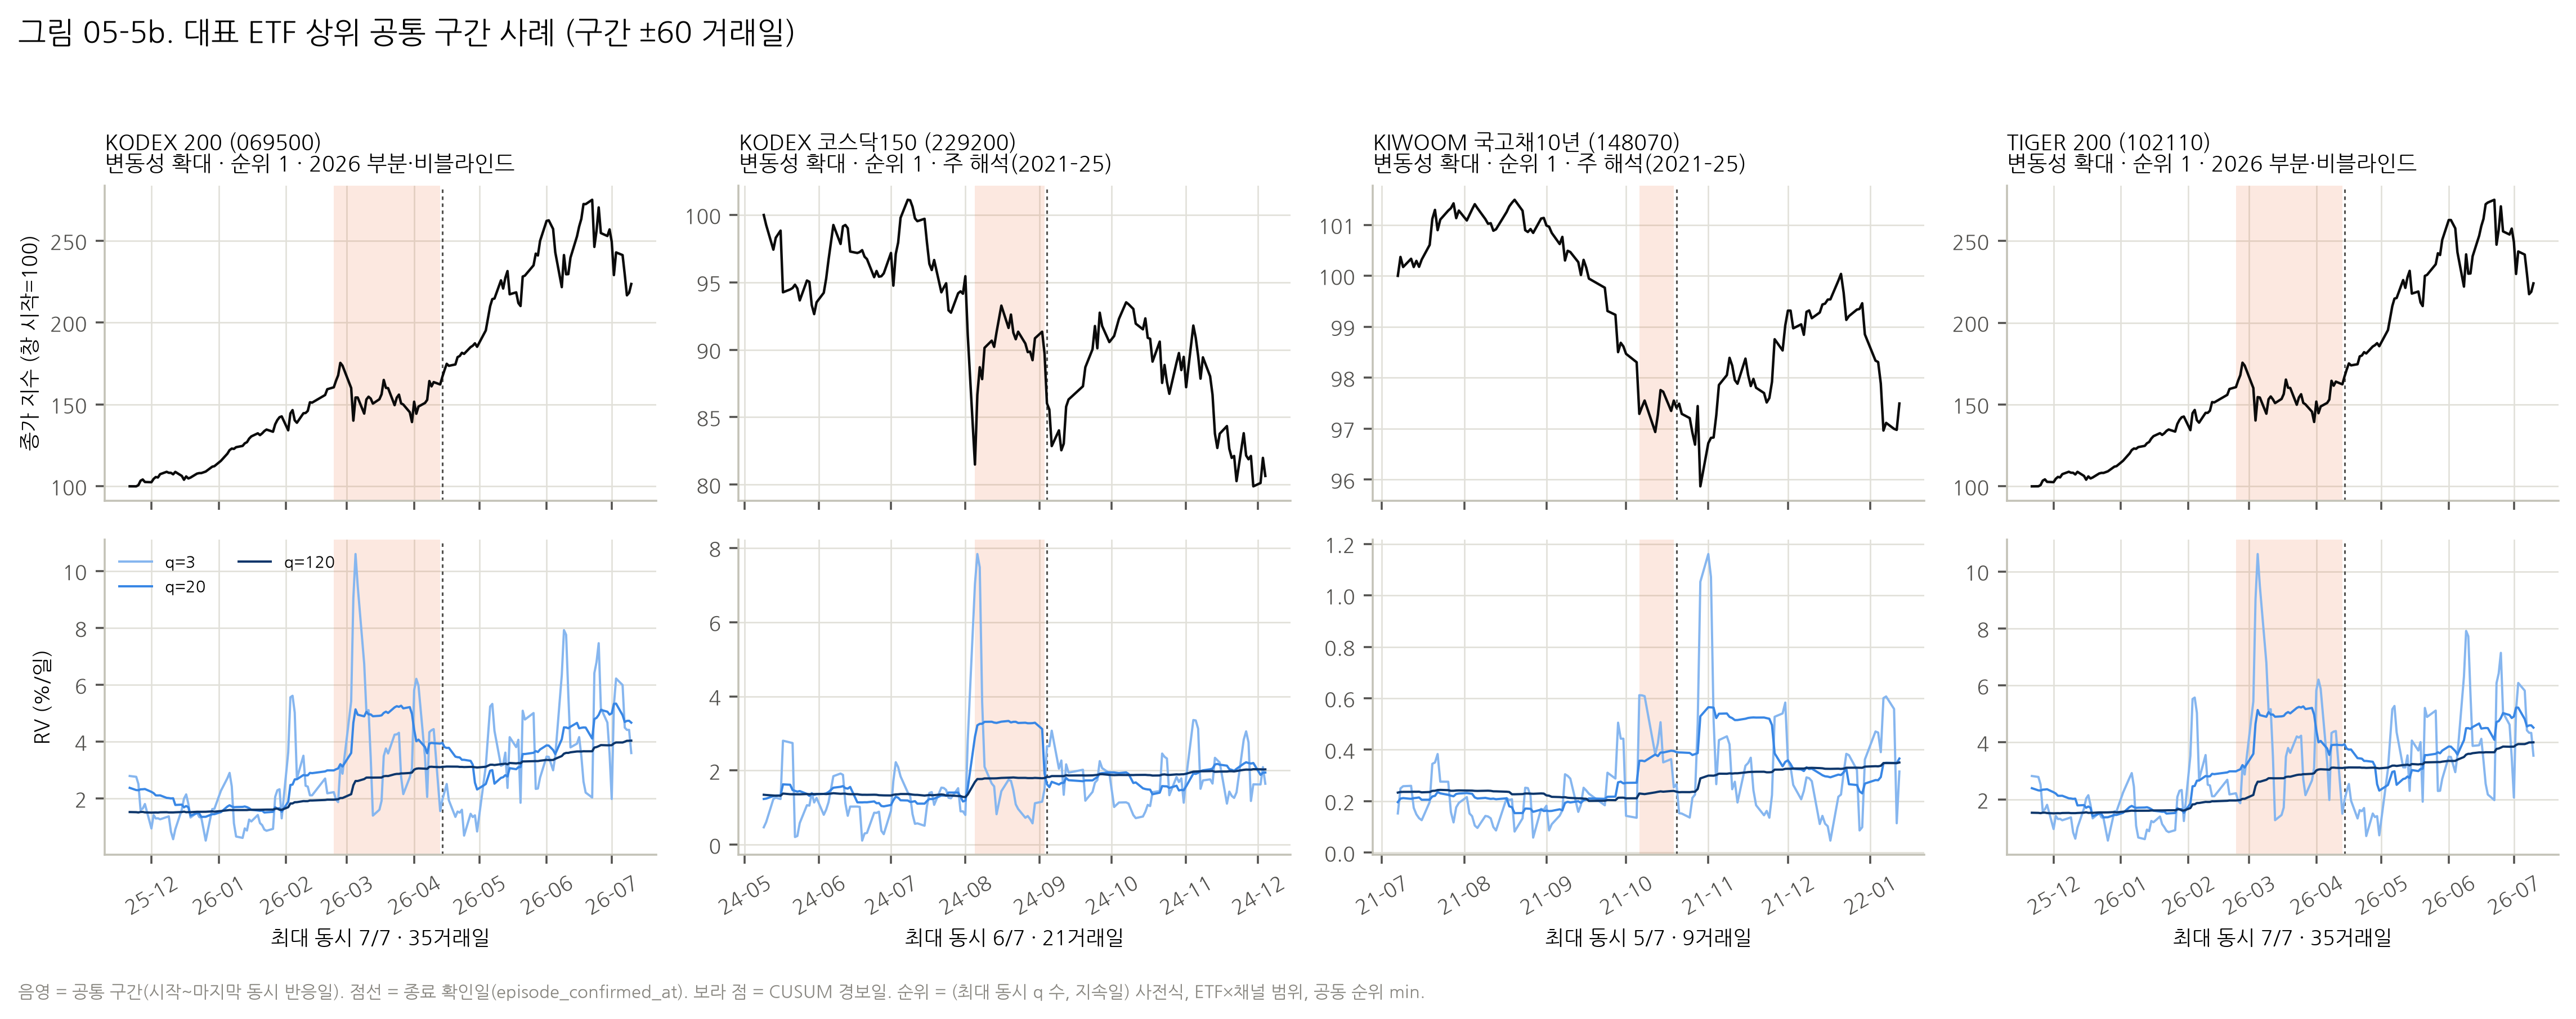

In [13]:
# 그림 05-5: 대표 4종 각각의 고변동성·확대 채널 1위 공통 구간 (구간 ±60 거래일).
for ch, k in (("HIGH_LEVEL", "a"), ("EXPANSION", "b")):  # 두 채널
    cases = []  # 사례 입력
    for t in REP:  # 대표 4종
        row = TOP[(TOP.ticker == t) & (TOP.channel == ch)].iloc[0]  # 1위 구간
        close = S05["prices"][t].set_index("Date").Close  # 종가
        alarm_any = MAIN_C.loc[t][[f"pipe_common_w{w}" for w in CFG["cusum_windows"]]].eq("ALARM").any(axis=1)  # 경보일
        cases.append(F.build_case(row, close, FEAT[FEAT.ticker == t], alarm_any))  # 사례 데이터
    FIG_FILES += F.case_zoom(cases, FIG, f"05-5{k}")  # 저장
    display(Image(filename=str(FIG_FILES[-2]), width=900))  # 표시

**그림 05-5 해석.**
- 고변동성 1위 구간 (05-5a): 주식형 3종(069500·229200·102110)은 2026 구간이다. 국고채10년은 2022-03-28 ~ 08-02 구간이다.
- 확대 1위 구간 (05-5b)은 수준 1위 구간보다 훨씬 짧다.
  - 069500·102110: 2026-02-23 ~ 04-13 (35일)
  - 229200: 2024-08 초 (21일)
  - 148070: 9일, 5/7
- 가격 방향이 섞여 있다. 같은 '변동성 확대' 안에 하락 급변과 상승 급변이 모두 있다.
- 가격 방향은 이 연구의 신호 정의에 들어가지 않는다 (D1). 방향별 반응은 07 에서 분리한다.

## 12. 기존 CUSUM 일별 경보의 재계산과 W1 대조

W1 은 일별 경보를 저장하지 않았다. 그래서 T12 잔차 `e` 와 W1 동결 임계값으로 다시 만든다. 재계산한 값은 W1 의 `04_real/alarm_metrics.csv` 와 행 단위로 일치해야 한다. 대조 항목은 다음과 같다.
- 종목·연도·정책·창
- 임계값 2종 × 표본 2종 = 6,720 행
- 유효일, 경보일, 에피소드 수, 첫 경보일

일치하지 않으면 이 노트북은 멈춘다.

In [14]:
# W1 대조: 재계산한 일별 경보로 W1 집계를 행 단위로 재현한다.
VER = S05["verify"]  # 대조표
assert VER._merge.eq("both").all() and VER.match.all(), VER[~VER.match].head()  # 6,720 행 전부 일치해야 한다
print("W1 alarm_metrics 재현:", int(VER.match.sum()), "/", len(VER), "행 일치 (유효일·경보일·에피소드·첫 경보일)")  # 결과
# 연도 경계 검사: 매년 첫 날 공통일 표본은 계산 불가여야 하고, 연도를 넘는 창은 없다.
first_days = CUS.sort_values("date").groupby(["ticker", "year", "policy"]).head(CFG_W1["common_start_zero_based"])  # 각 연도 처음 119 거래일
assert first_days[[f"pipe_common_w{w}" for w in CFG["cusum_windows"]]].eq("NOT_AVAILABLE").all().all()  # 공통일 시작 전은 NOT_AVAILABLE
w120_first = CUS.sort_values("date").groupby(["ticker", "year", "policy"]).head(119)  # w=120 창이 차기 전 119일
assert w120_first["pipe_own_w120"].eq("NOT_AVAILABLE").all() and w120_first["T_w120"].isna().all()  # own 표본도 연도 경계를 넘지 않는다
print("연도 경계 검사 통과: 연초 119 거래일은 공통일 표본에서 모두 NOT_AVAILABLE, w=120 own 표본도 창이 차기 전 계산 없음")  # 결과

W1 alarm_metrics 재현: 6720 / 6720 행 일치 (유효일·경보일·에피소드·첫 경보일)
연도 경계 검사 통과: 연초 119 거래일은 공통일 표본에서 모두 NOT_AVAILABLE, w=120 own 표본도 창이 차기 전 계산 없음


## 13. 기존 CUSUM 과의 관계 (H3)

**질문.** 실현분산의 높은 수준(U_V), 직전 대비 변화(D), W1 CUSUM 통계량 T_w 는 서로 어떻게 관련되는가?

**미리 밝혀 둘 구조.** `rolling_cusum` 코드(T12·W1 원본)를 보면 세 가지가 확인된다.
1. 입력은 SVR–GARCH 예측분산으로 나눈 표준화 잔차 $e_t=r_t/\sqrt{\hat v_t}$ 다.
2. 통계량은 창 안의 제곱 누적합 경로의 최대 절대 편차다. 즉 양측이다.
3. 그 편차를 **창 자신의** 4차 적률 기반 $\hat\tau$ 로 나눈다.

그래서 T_w 는 창 전체의 변동성 수준에 대해 척도 불변이다. 측정하는 것은 '예측분산 대비 잔차 분산이 창 **안에서** 바뀌었는가' 이고, 상승과 하락 모두에 반응한다.

따라서 RV 수준과 T 의 상관이 약하더라도, 그것은 곧바로 CUSUM 이 틀렸다는 증거가 아니다. 두 양은 측정 대상이 다르다. 반대로 상관이 강하더라도, 같은 수익률에서 나온 값이므로 독립 검증이 아니다.

**표본.** 2021–2025, 정책 A, W1 연간 임계값, 공통일이다. 정책 B·base, own_pure 표본, T12 점별 임계값은 병렬 민감도로 둔다.

In [15]:
# H3 표: (1) Spearman ρ 의 ETF 중앙값 (q=w 대각), (2) 경보일 대 비경보일 U_V 분위, (3) 구간–CUSUM 커버리지.
SP = S05["spearman"]  # ETF × q × w × 변수 × 정책
diag = SP[(SP.q == SP.w)].groupby(["policy", "variable", "w"]).spearman.median().unstack("w").round(3)  # q=w 대각의 ETF 중앙값
display(diag)  # 수준·변화와 T 의 순위상관
CT = S05["contrast"]  # 경보/비경보 분포
ct = CT[CT.q == CT.w].pivot_table(index=["variant", "w"], columns="state", values=["median_U_V", "share_U_V_ge_090", "n_days", "n_etf"]).round(3)  # q=w 비교
display(ct)  # 경보일 수가 작은 칸(w=20)은 해석하지 않는다
cov = {v: (P_IV[f"cusum_{p}alarm_w"].value_counts().reindex(["NONE", "NOT_AVAILABLE"]).fillna(0).astype(int).to_dict() | {"ALARM_겹침": int((~P_IV[f"cusum_{p}alarm_w"].isin(["NONE", "NOT_AVAILABLE"])).sum()), "평균_커버리지": round(float(P_IV[f"cusum_{p}coverage"].mean()), 3)}) for v, p in (("주(A·연간·공통일)", ""), ("A·own_pure", "A_own_"), ("A·T12 점별", "A_point_"), ("B", "B_"), ("base", "base_"))}  # 변형별 구간 겹침
display(pd.DataFrame(cov).T)  # 2021–2025 공통 구간 1,168개 중 CUSUM 경보가 겹친 구간 수와 계산 가능 비율

w                  20     30     60     120
policy variable                            
A      D         0.072  0.038  0.078 -0.027
       U_V      -0.012 -0.094 -0.106 -0.064
B      D         0.015  0.041  0.050 -0.093
       U_V       0.028 -0.004 -0.071 -0.055
base   D         0.120  0.093 -0.000 -0.091
       U_V      -0.003 -0.010 -0.003 -0.237

median_U_V          n_days          n_etf          share_U_V_ge_090         
state            ALARM NO_ALARM  ALARM NO_ALARM ALARM NO_ALARM            ALARM NO_ALARM
variant w                                                                               
A_own   20       0.295    0.554    5.0  22577.0   5.0     20.0            0.200    0.104
        30       0.570    0.552   33.0  21567.0   8.0     20.0            0.364    0.106
        60       0.275    0.526  114.0  18486.0  12.0     20.0            0.360    0.096
        120      0.842    0.501  149.0  12451.0   7.0     20.0            0.295    0.061
A_point 20       0.628    0.554  253.0  12337.0  20.0     20.0            0.249    0.113
        30       0.567    0.548  125.0  12465.0  17.0     20.0            0.328    0.112
        60       0.262    0.523  125.0  12465.0  13.0     20.0            0.368    0.104
        120      0.531    0.500  197.0  12393.0   7.0     20.0            0.284    0.060
B       20       0.394    0.556    8.0  12592.0   3.0     20.0            0.000    0.116
        30       0.903    0.548   15.0  12585.0   4.0     20.0            0.533    0.114
        60       0.791    0.521   40.0  12560.0   4.0     20.0            0.475    0.106
        120      0.684    0.500  136.0  12464.0   4.0     20.0            0.000    0.064
base    20       0.537    0.556    6.0  12594.0   4.0     20.0            0.000    0.116
        30       0.871    0.548    6.0  12594.0   3.0     20.0            0.167    0.114
        60       0.249    0.523    1.0  12599.0   1.0     20.0            0.000    0.107
        120      0.633    0.501   11.0  12589.0   1.0     20.0            0.000    0.064
main    20       0.582    0.555    2.0  12588.0   2.0     20.0            0.500    0.116
        30       0.621    0.548   28.0  12562.0   6.0     20.0            0.429    0.113
        60       0.262    0.523  103.0  12487.0  11.0     20.0            0.379    0.105
        120      0.842    0.501  149.0  12441.0   7.0     20.0            0.295    0.061

,NONE,NOT_AVAILABLE,ALARM_겹침,평균_커버리지
주(A·연간·공통일),639.0,496.0,33.0,0.562
A·own_pure,1056.0,73.0,39.0,0.933
A·T12 점별,587.0,496.0,85.0,0.562
B,661.0,495.0,12.0,0.562
base,666.0,495.0,7.0,0.562


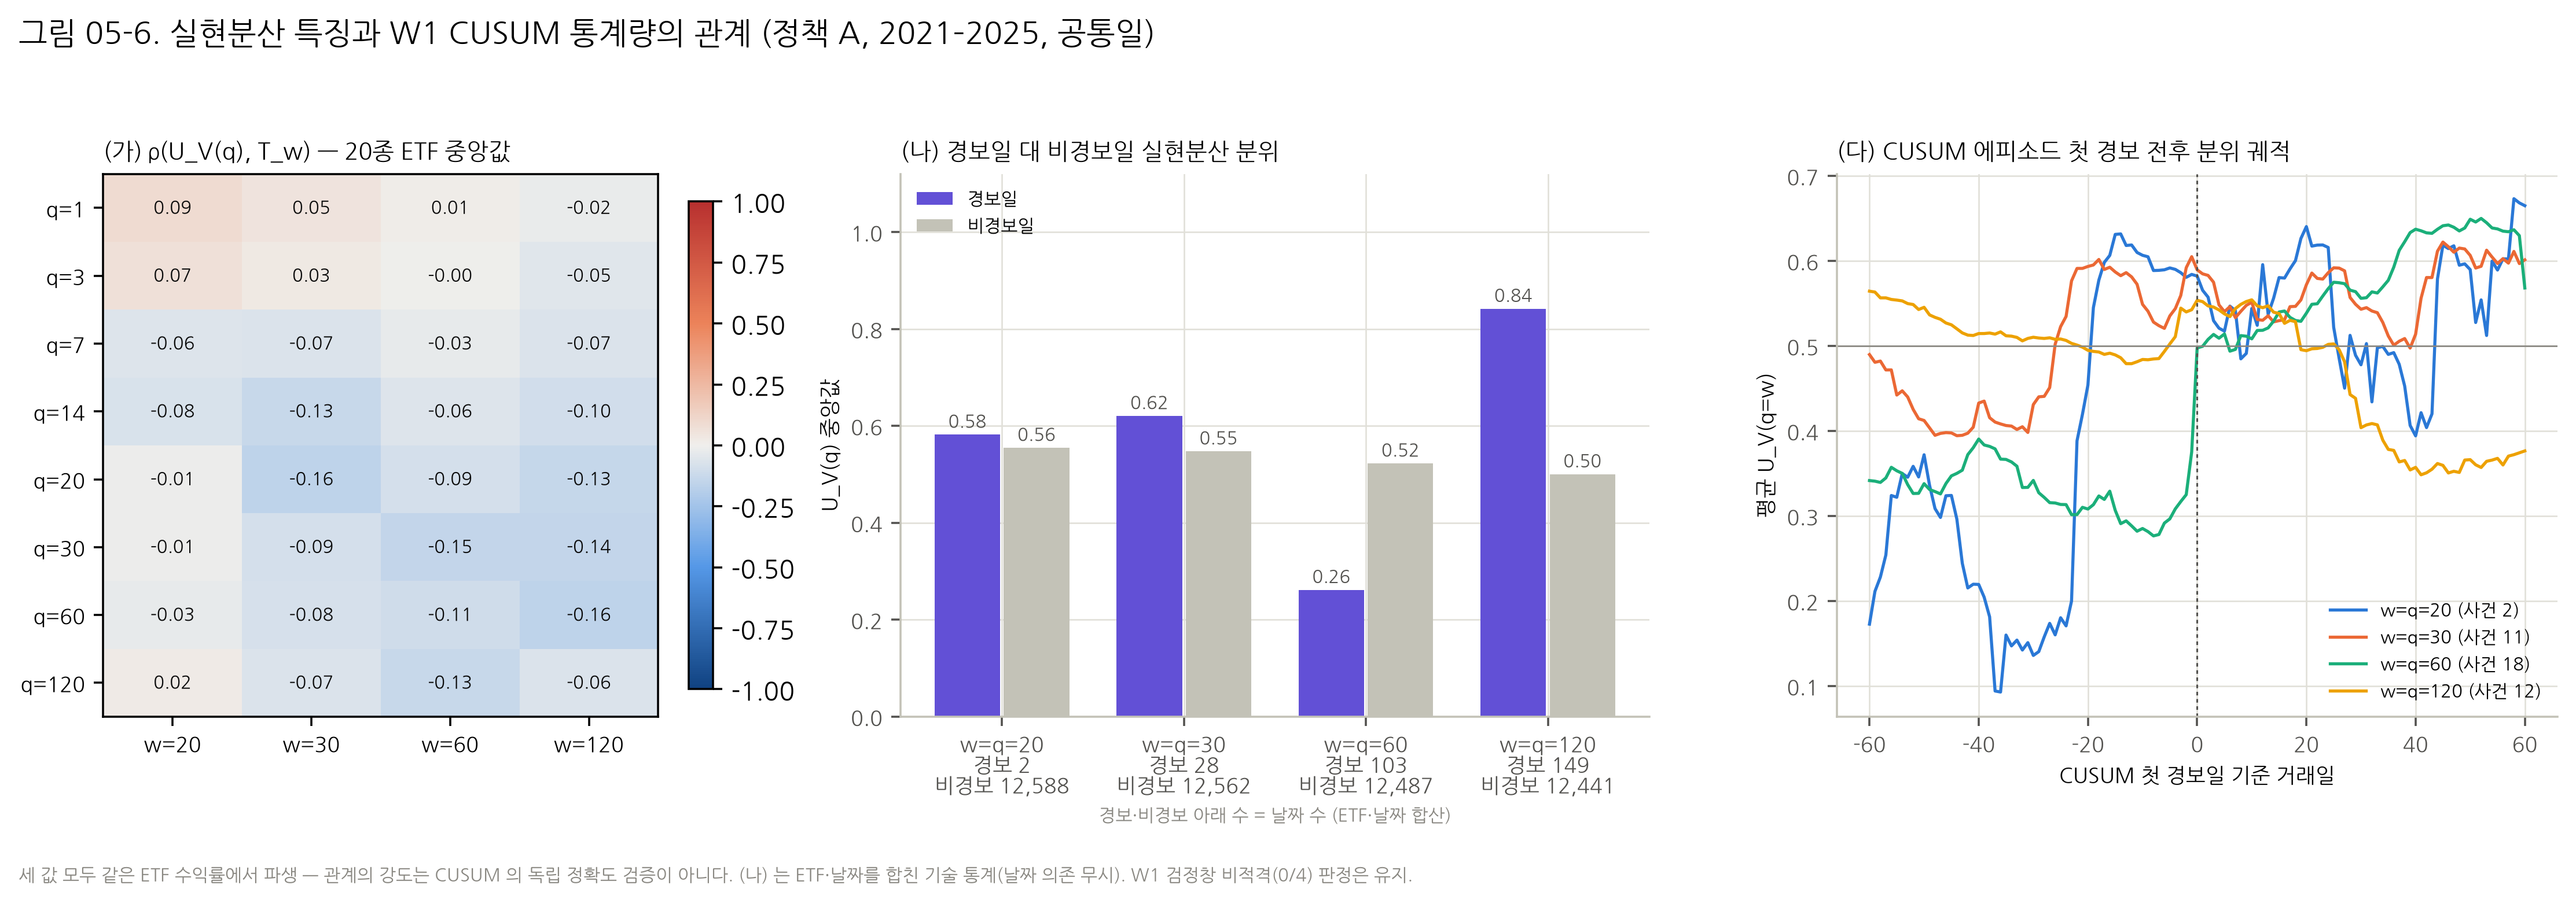

사건 수 (2021–2025, 정책 A·연간 임계값·공통일): {20: 2, 30: 11, 60: 18, 120: 12} | 2020–2026 전체: {20: 2, 30: 16, 60: 30, 120: 36}


In [16]:
# 그림 05-6: ρ 행렬 · 경보/비경보 분위 · 경보 전후 사건 궤적.
FIG_FILES += F.rv_cusum_relation(SP[SP.policy == "A"], CT[CT.variant == "main"], S05["event_traj"], FIG, "05-6", tuple(CFG["core_years"]))  # 저장 (사건 궤적도 2021–2025)
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시
EVN = S05["events"]  # CUSUM 에피소드 첫 경보 사건
print("사건 수 (2021–2025, 정책 A·연간 임계값·공통일):", EVN[EVN.year.isin(CFG["core_years"])].groupby("w").size().to_dict(), "| 2020–2026 전체:", EVN.groupby("w").size().to_dict())  # 창별 사건 수

**H3 해석 — 지지하는 관찰과 지지하지 않는 관찰을 나란히.**

| | 관찰 (2021–2025, 정책 A) |
|---|---|
| 관계 있음 쪽 | w=120 경보일의 U_V⁽¹²⁰⁾ 중앙값은 0.84 로 비경보일 0.50 보다 높다 (경보일 149일·7종). w=30 은 0.62 대 0.55 (28일·6종) |
| 관계 없음·반대 쪽 | ρ(U_V⁽q=w⁾, T_w) 의 ETF 중앙값은 −0.11 ~ −0.01 이다. w=60 경보일의 U_V⁽⁶⁰⁾ 중앙값은 0.26 으로 비경보일 0.52 보다 **낮다** (103일·11종) |
| 해석 불가 | w=20 경보일은 2일·사건 2건뿐이라 분포를 해석하지 않는다 |
| 비교 가능 범위 | 2021–2025 공통 구간 1,168개 가운데 주 CUSUM 이 하루도 계산되지 않은 구간이 496개다. 평균 계산 가능 비율은 0.56 이다. own_pure 표본에서는 그런 구간이 73개, 비율은 0.93 이다 |

**대안 설명.** w=60 경보가 낮은 RV 수준과 함께 나오는 것은 위의 구조로 설명될 수 있다. CUSUM 은 양측이고 척도 불변이다. 그래서 고변동성이 **가라앉는** 창이나, 낮은 변동성 안의 상대적 변화에도 반응한다. 이번 계약은 경보의 방향(상승/하락)을 나누지 않았으므로, 이 설명을 검증하지 않았다.

**결론의 범위.**
- 'RV 수준이 높은 날에 CUSUM 이 더 자주 경보한다' 는 w=120 에서만 기술적으로 관찰된다. 창마다 방향이 일관되지 않다.
- 세 값이 같은 수익률에서 나왔으므로, 어느 쪽도 CUSUM 의 정확도 검증이 아니다.
- W1 의 검정창 비적격(0/4) 판정은 그대로다.

## 14. 통계적 해석·대안 설명·제약

### 가설별 판정 (계약 [A-13]: 지지 / 비지지 를 같은 형식으로)

In [17]:
# 주장–근거 대조: 본문에 적은 수치를 실제 결과에서 다시 계산해 일치를 확인한다 (불일치면 멈춘다).
JAC = S05["jaccard"]  # ETF 별 고변동성 후보일 대 확대 후보일 Jaccard
SENS = S05["sensitivity"]  # 임계값·기준분포 민감도
CLAIMS = {  # 본문 수치
    # 본문 주장 (계산값, 본문값)
    "W1 대조 일치 행": (int(VER.match.sum()), 6720),
    # 본문 주장 (계산값, 본문값)
    "2021–25 공통 구간 HIGH/EXP/LOW/CON": (tuple(P_IV.channel.value_counts().reindex(["HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION"]).astype(int)), (290, 253, 363, 262)),
    # 본문 주장 (계산값, 본문값)
    "2021–25 7/7 구간 HIGH/EXP/LOW/CON": (tuple(P_IV[P_IV.max_overlap_count == 7].channel.value_counts().reindex(["HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION"]).fillna(0).astype(int)), (23, 2, 9, 0)),
    # 본문 주장 (계산값, 본문값)
    "주 CUSUM 미계산 구간 / 전체": ((int((P_IV.cusum_alarm_w == "NOT_AVAILABLE").sum()), len(P_IV)), (496, 1168)),
    # 본문 주장 (계산값, 본문값)
    "주 CUSUM 경보 겹침 구간": (int((~P_IV.cusum_alarm_w.isin(["NONE", "NOT_AVAILABLE"])).sum()), 33),
    # 본문 주장 (계산값, 본문값)
    "own_pure 미계산 구간": (int((P_IV.cusum_A_own_alarm_w == "NOT_AVAILABLE").sum()), 73),
    # 본문 주장 (계산값, 본문값)
    "ρ 중앙값 A q=w (20,30,60,120)": (tuple(diag.loc[("A", "U_V")].round(2)), (-0.01, -0.09, -0.11, -0.06)),
    # 본문 주장 (계산값, 본문값)
    "w120 경보/비경보 U_V 중앙값": (tuple(CT[(CT.variant == "main") & (CT.w == 120) & (CT.q == 120)].set_index("state").median_U_V.reindex(["ALARM", "NO_ALARM"]).round(2)), (0.84, 0.5)),
    # 본문 주장 (계산값, 본문값)
    "w60 경보/비경보 U_V 중앙값": (tuple(CT[(CT.variant == "main") & (CT.w == 60) & (CT.q == 60)].set_index("state").median_U_V.reindex(["ALARM", "NO_ALARM"]).round(2)), (0.26, 0.52)),
    # 본문 주장 (계산값, 본문값)
    "고변동성·확대 후보일 Jaccard 중앙값 (최소, 최대)": ((round(float(JAC.jaccard.median()), 2), round(float(JAC.jaccard.min()), 2), round(float(JAC.jaccard.max()), 2)), (0.27, 0.07, 0.59)),
    # 본문 주장 (계산값, 본문값)
    "고변동성 후보일 중 확대 후보일과 겹친 비율 (20종 합산)": (round(JAC.n_both.sum() / JAC.n_high_days.sum(), 2), 0.29),
    # 본문 주장 (계산값, 본문값)
    "ETF×채널 1위 2026 시작 (전체, 고변동성, 확대)": ((int((TOP.year_status == "PARTIAL_NON_BLIND").sum()), int(((TOP.year_status == "PARTIAL_NON_BLIND") & (TOP.channel == "HIGH_LEVEL")).sum()), int(((TOP.year_status == "PARTIAL_NON_BLIND") & (TOP.channel == "EXPANSION")).sum())), (28, 14, 10)),
    # 본문 주장 (계산값, 본문값)
    "민감도 1위 구간 유지 (5% 축소)": (int(SENS[(SENS.variant == "sens_5pct") & (SENS.channel == "CONTRACTION")].top1_overlap_retained.iloc[0]), 10),
    # 본문 주장 (계산값, 본문값)
    "민감도 1위 구간 유지 (그 외 15칸 모두 20/20)": (bool(SENS[~((SENS.variant == "sens_5pct") & (SENS.channel == "CONTRACTION"))].top1_overlap_retained.eq(20).all()), True),
}  # 끝
for k, (got, want) in CLAIMS.items():  # 하나씩
    assert got == want, f"{k}: 계산 {got} ≠ 본문 {want}"  # 본문 수치 불일치면 중단
    print(f"✓ {k}: {got}")  # 확인
display(JAC.sort_values("jaccard").reset_index(drop=True))  # ETF 별 Jaccard
display(SENS.pivot_table(index="channel", columns="variant", values=["n_intervals_core", "n_max7_core", "top1_overlap_retained"]))  # 민감도 표

✓ W1 대조 일치 행: 6720
✓ 2021–25 공통 구간 HIGH/EXP/LOW/CON: (290, 253, 363, 262)
✓ 2021–25 7/7 구간 HIGH/EXP/LOW/CON: (23, 2, 9, 0)
✓ 주 CUSUM 미계산 구간 / 전체: (496, 1168)
✓ 주 CUSUM 경보 겹침 구간: 33
✓ own_pure 미계산 구간: 73
✓ ρ 중앙값 A q=w (20,30,60,120): (-0.01, -0.09, -0.11, -0.06)
✓ w120 경보/비경보 U_V 중앙값: (0.84, 0.5)
✓ w60 경보/비경보 U_V 중앙값: (0.26, 0.52)
✓ 고변동성·확대 후보일 Jaccard 중앙값 (최소, 최대): (0.27, 0.07, 0.59)
✓ 고변동성 후보일 중 확대 후보일과 겹친 비율 (20종 합산): 0.29
✓ ETF×채널 1위 2026 시작 (전체, 고변동성, 확대): (28, 14, 10)
✓ 민감도 1위 구간 유지 (5% 축소): 10
✓ 민감도 1위 구간 유지 (그 외 15칸 모두 20/20): True


,ticker,n_high_days,n_expansion_days,n_both,jaccard
0,148070,319,32,23,0.070122
1,261240,170,39,26,0.142077
2,091230,196,42,32,0.155340
3,143860,31,18,7,0.166667
4,132030,106,47,25,0.195312
5,219480,94,38,22,0.200000
6,305540,183,44,42,0.227027
7,117680,167,71,50,0.265957
8,229200,111,46,33,0.266129
9,091170,84,65,32,0.273504


n_intervals_core                                    n_max7_core                                 top1_overlap_retained                                
variant       fixed504_10pct main_10pct sens_20pct sens_5pct fixed504_10pct main_10pct sens_20pct sens_5pct        fixed504_10pct main_10pct sens_20pct sens_5pct
channel                                                                                                                                                          
CONTRACTION            330.0      262.0     1173.0      52.0            0.0        0.0        0.0       0.0                  20.0       20.0       20.0      10.0
EXPANSION              361.0      253.0      997.0     102.0            5.0        2.0        7.0       1.0                  20.0       20.0       20.0      20.0
HIGH_LEVEL             344.0      290.0      529.0     125.0           48.0       23.0       51.0      11.0                  20.0       20.0       20.0      20.0
LOW_LEVEL              488.0      363.0      594.0     195.0           31.0        9.0       42.0       2.0                  20.0       20.0       20.0      20.0

| 가설 | 지지하는 관찰 | 지지하지 않는·제한하는 관찰 |
|---|---|---|
| **H1** 개별 ETF 상태 변화 | 20종 모두 과거 분위 상·하위 10% 상태가 반복된다. 수준과 변화는 다른 날을 가리킨다 (고변동성·확대 후보일 Jaccard 중앙값 0.27, 범위 0.07–0.59. 고변동성 후보일 중 확대 후보일이기도 한 날은 0.29) | 분위는 자기 과거 기준의 탐색 척도다. 2020 급락이 기준분포 상단을 차지해 긴 q 신호 비율이 0.04–0.09 로 낮다. 확증적 기각이 아니다 |
| **H2** 다중 기간 공통성 | 2021–2025 공통 구간 1,168개. 7/7 동시 구간이 고변동성 23·저변동성 9·확대 2 | 7개 기간은 같은 수익률을 공유한다. 중첩 귀무분포를 보정하지 않았으므로 '유의한 공통 구간' 이 아니다. 확대·축소 7/7 은 드물다 (2·0) |
| **H3** RV–CUSUM | w=120 경보일 U_V 중앙값 0.84 > 비경보일 0.50 | ρ 중앙값 −0.11~−0.01. w=60 은 반대 방향(0.26 < 0.52). 공통 구간의 42%(496/1,168)는 CUSUM 계산 불가 |

**민감도.**
- 5%·20% 기준과 고정 504일 기준분포에서 구간 **수**는 크게 바뀐다. 예: 20% 기준 축소 구간 1,173개.
- 그러나 각 ETF·채널의 1위 구간 날짜는 16칸 가운데 15칸에서 20/20 이 유지된다. 예외는 5% 기준 축소 채널(10/20)이다.
- 주 결과는 10%·확장형 그대로다.

**대안 설명과 제약.**
1. **기준분포 효과.** 2019–2020 의 몇 달이 분위의 상단을 정한다. 같은 RV 라도 언제 평가하느냐에 따라 분위가 달라진다. 이 효과는 고정 504일 민감도에서 일부 드러난다 (고변동성 2021–25 구간 290 → 344).
2. **중첩 창 의존.** 날짜·q·ETF 사이의 강한 의존 때문에 구간 수를 독립 시행으로 세지 않는다.
3. **2026 편중.** 전체 순위 1위의 상당수가 부분·비블라인드 연도다.
4. **원자료 정의.** FDR 종가는 분배 소급조정 추정치다. O/H/L 일관성은 보장되지 않는다 (C-0012 DEC-3).
5. **사후 구간.** 시작일은 사후에 정한 구간 시작이다. 실시간 조기경보 시점이 아니다. 확인일은 `episode_confirmed_at` 이다.

## 15. 재현성 및 결과 검증 — 06 으로의 인계

In [18]:
# 그림 색인·결과 해시를 기록하고 05→06 인계 파일을 쓴다.
fig_index = pd.DataFrame({"file": [str(p.relative_to(BASE)) for p in FIG_FILES], "sha256": [sha256(p) for p in FIG_FILES]})  # 그림 해시
fig_index.to_csv(BASE / "results/05/figure_index_05.csv", index=False)  # 그림 색인 저장
MAN = S05["manifest"]  # 05 결과 해시
handoff = {"from": "05", "to": "06", "protocol_version": CFG["protocol_version"], "config_sha256": FREEZE[0][0], "contract_sha256": FREEZE[1][0], "t12_run_id": CFG["t12_run_id"], "environment": ACTUAL_ENV, "results": MAN["files_sha256"], "work_files": MAN["work_sha256"], "figure_index_sha256": sha256(BASE / "results/05/figure_index_05.csv")}  # 인계 내용
(BASE / "results/05_to_06.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")  # 인계 파일 저장
display(pd.Series(MAN["files_sha256"]).rename("sha256").to_frame())  # 결과 CSV 해시
print("그림", len(FIG_FILES) // 2, "개 (PNG 320dpi + SVG) · 인계 파일:", BASE / "results/05_to_06.json")  # 요약

,sha256
results/05/h3_spearman.csv,f83571b83b84b337c656229550b14f54b80146e2ebc1e3...
results/05/h3_alarm_contrast.csv,92692e4af7765e1fb25307e9b677b758663963437fafa2...
results/05/h3_cusum_events.csv,14adb328ab4a6288068f5d9e9c7acdd183ea9a9aa6b080...
results/05/h3_event_trajectory_mean.csv,c660c3c0aab5ddb02890bed8426298a0efdea59af72d3a...
results/05/h1_level_vs_change_jaccard.csv,43e5d0d633bdbd605090e35781e2e66e2a5876319bcbbe...
results/05/eligibility_missingness.csv,bd7cf1e5941067d5fc6d919a2e1f100792a225a4257aef...
results/05/signal_rates.csv,d8a5526618942dc40e38462ac4cdf42ca8e39e8cc47e93...
results/05/period_episodes.csv,f48a03c087506a626fff4ec3973cd60457fe0a02387184...
results/05/overlap_intervals.csv,3b007bf9c1bb1a11d8ba9c6033016dd3f19c5a25a39a1d...
results/05/cusum_w1_reconciliation.csv,e79b2a08d28eb12866fc0dca52e3d9153bc0e0d166bde6...


그림 11 개 (PNG 320dpi + SVG) · 인계 파일: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017/R2H_MultiHorizon_Volatility_Regime/research/multihorizon_w2/results/05_to_06.json


**산출물 (Git 포함).** `research/multihorizon_w2/results/05/` 아래:
- `eligibility_missingness.csv`, `signal_rates.csv`, `period_episodes.csv`, `overlap_intervals.csv`
- `cusum_w1_reconciliation.csv`, `unit_checks.csv`, `sensitivity_intervals.csv`
- `h1_level_vs_change_jaccard.csv`, `h3_*.csv`
- `05_manifest.json`, `figure_index_05.csv`
- 인계 파일 `05_to_06.json`

**Git 제외.** 가격을 역산할 수 있는 일별 표는 `outputs/t14/05/` 에 둔다: `daily_features.csv.gz`, `daily_overlap.csv.gz`, `daily_cusum.csv.gz`. 해시만 인계 파일에 남긴다.

**다음 단계.** 06 은 이 인계 파일의 해시를 대조한 뒤, 같은 공통 구간을 노출 군집과 20종 전체로 확장한다.